# Spotify Genre Classification

### About the Dataset

This dataset is from Kaggle and contains Spotify tracks from a wide range of genres. 
The Kaggle page says 125 genres, but the file itself contains 114 genres with 1,000 tracks each, 
which gives 114,000 tracks in total. Each track has a set of audio features that describe 
how the song sounds, like how danceable, energetic or loud it is.

The data is in CSV format, which is tabular and quick to load with pandas.

Link: https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset

Credit goes to Maharshi Pandya.
### Goal

The goal is to predict the genre of a song based on its audio features. This is a multiclass 
classification problem, since there are more than two possible genres.

I compare two baseline models, three ensemble models and two neural networks, and I also want 
to understand which features separate the genres from each other.

##### Understanding the Audio Features

To help understand how the models separate the genres, here is a simple explanation of what each audio feature actually measures:

* **Popularity:** A score from 0 to 100 based on how many times a song has been played recently.
* **Duration_ms:** The length of the track measured in milliseconds.
* **Explicit:** A true/false (1 or 0) value showing if the song contains lyrics that are not suitable for children.
* **Danceability:** How suitable a track is for dancing based on tempo, rhythm stability, and beat strength (from 0.0 to 1.0).
* **Energy:** A measure from 0.0 to 1.0 representing intensity and activity. High energy feels fast, loud, and noisy (like heavy metal).
* **Key:** The overall key the track is in (e.g., C, C#, D) using standard pitch notation.
* **Loudness:** The overall loudness of a track in decibels (dB), usually ranging between -60 and 0 dB.
* **Mode:** The modality of a track (Major = 1, Minor = 0), which often defines if a song sounds "happy" or "sad".
* **Speechiness:** Detects the presence of spoken words. A value close to 1.0 means it is mostly talking (like a podcast or rap), while lower values mean music.
* **Acousticness:** A score from 0.0 to 1.0 showing how likely it is that the song uses acoustic instruments (like an acoustic guitar or piano) rather than electronic ones.
* **Instrumentalness:** Predicts whether a track contains no vocals. The closer to 1.0, the more likely the song has no singing at all.
* **Liveness:** Detects the presence of an audience in the recording. Higher values mean the song was probably recorded live at a concert.
* **Valence:** A measure from 0.0 to 1.0 describing the musical positiveness. High valence sounds happy/cheerful, while low valence sounds sad/angry.
* **Tempo:** The overall speed of the track measured in Beats Per Minute (BPM).
* **Time_signature:** An estimated overall time signature of a track (e.g., 3/4 or 4/4 bar). - time_signature: The number of beats within each bar of the track. (Integer)


* **Unnamed: 0:** A leftover row number from when the file was saved. Not a real feature.
* **Track_id:** Spotify's unique ID for each track.
* **Artists, Album_name, Track_name:** Who made the song, which album it's from, and its title.
* **Track_genre:** The genre of the track. **This is the label we want to predict.**



# EXPLORATORY DATA ANALYSIS

In [228]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

from itertools import combinations
import plotly.express as px


from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, PowerTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import multilabel_confusion_matrix
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import ExtraTreesClassifier 
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from scikeras.wrappers import KerasClassifier
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.preprocessing import label_binarize


import os
import keras




In [131]:
df = pd.read_csv("../dataset/spotify.csv")


In [132]:
df.head(10) # checking the data and their rows

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
5,5,01MVOl9KtVTNfFiBU9I7dc,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,214240,False,0.688,0.4810,...,-8.807,1,0.1050,0.2890,0.000000,0.1890,0.6660,98.017,4,acoustic
6,6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,0.1470,...,-8.822,1,0.0355,0.8570,0.000003,0.0913,0.0765,141.284,3,acoustic
7,7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,242946,False,0.703,0.4440,...,-9.331,1,0.0417,0.5590,0.000000,0.0973,0.7120,150.960,4,acoustic
8,8,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.4140,...,-8.700,1,0.0369,0.2940,0.000000,0.1510,0.6690,130.088,4,acoustic
9,9,7k9GuJYLp2AzqokyEdwEw2,Ross Copperman,Hunger,Hunger,56,205594,False,0.442,0.6320,...,-6.770,1,0.0295,0.4260,0.004190,0.0735,0.1960,78.899,4,acoustic


In [133]:
df.shape # Tells us the amount of instances and features in the dataset 


(114000, 21)

In [134]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

### Interpretation

The dataset contains 114,000 rows and 21 columns. Most columns have complete data, but `artists`, 
`album_name` and `track_name` each have one missing value.

There are 1 bool, 9 float, 6 integer and 5 text columns. Some integer columns are really 
categories: `key`, `mode` and `time_signature`. A higher number there does not mean "more", 
so they need to be handled as categories later.

#### Missing values

`info()` showed that `artists`, `album_name` and `track_name` each have one missing value. 
Here I check exactly where they are, and whether it is the same row.

In [135]:
df.isnull().sum() # checking for null values in the dataset

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [136]:
df[df['artists'].isnull()]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


#### Interpretation

`artists`, `album_name` and `track_name` are all missing in the same row. This row also has 
`duration_ms = 0`, which is not possible for a real song, so it looks like a broken entry.

Since it is only 1 row out of 114,000, removing it will not affect the analysis. 
I will drop it in preprocessing.

#### Duplicates

Here I check if the dataset counts some songs more than once. Copies can make the model 
see the same song in both training and test data, which gives results that look better 
than they really are.

In [137]:
# Check for exact duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


In [138]:
# Check duplicates without the index column
duplicates = df.drop(columns='Unnamed: 0').duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 450


In [139]:
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


In [140]:
# Comparing the number of rows with the number of unique songs.
# The same track_id means the same song.
print(f"Total rows: {len(df)}")
print(f"Unique songs: {df['track_id'].nunique()}")
print(f"Repeated songs: {df['track_id'].duplicated().sum()}")

Total rows: 114000
Unique songs: 89741
Repeated songs: 24259


Unique songs (89,741): every different song, counted once.

Repeated songs (24,259): every extra time a song shows up after its first appearance



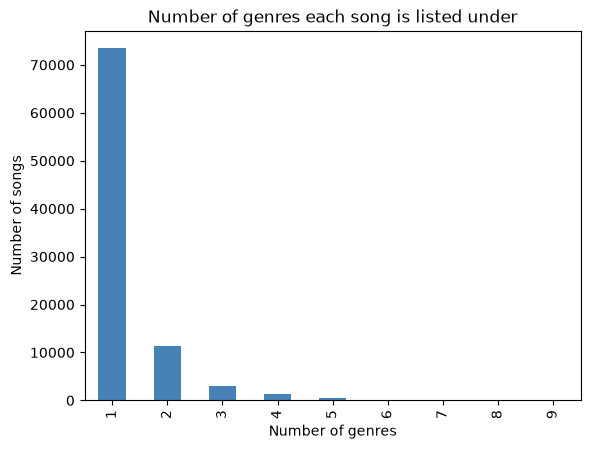

In [141]:
# How many different genres is each song listed under?
genres_per_song = df.groupby('track_id')['track_genre'].nunique()

genres_per_song.value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Number of genres each song is listed under')
plt.xlabel('Number of genres')
plt.ylabel('Number of songs')
plt.show()

In [142]:
print(genres_per_song.value_counts().sort_index())

track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64


In [143]:
# Check if repeated songs have the same audio values
audio = ['danceability', 'energy', 'tempo', 'loudness', 'valence']
print(f"Repeats with the same audio values: {df.duplicated(subset=['track_id'] + audio).sum()}")

Repeats with the same audio values: 24259


#### Interpretation

At first it looked like there were no duplicates, but that was because `Unnamed: 0` gives every 
row its own number. Without it, there are 450 rows that are exact copies.

There are also fewer unique songs than rows, so many songs appear more than once. The plot shows 
that most songs belong to one genre, but a lot of songs are listed under two or more. When a song 
appears again, its audio values are exactly the same. Only the genre is different.

This is a problem for two reasons. The model sees the same song with different answers, so it 
can't learn what separates those genres. And copies of the same song could end up in both the 
training and test data, which would make the results look better than they really are.

I will handle this in preprocessing.

### Summary statistics

Here I look at the basic numbers for each numeric column: the average, the smallest and largest 
value, and how spread out the values are. The goal is to spot values that look wrong or unrealistic.#

In [144]:
# Summary statistics for all numeric columns.
# .T flips the table so each column becomes a row, which is easier to read.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500000,32909.109681,0.000,28499.75000,56999.500000,85499.2500,113999.000
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996


count: how many values

mean: the average

std: how spread out the values are

min / max: the smallest and largest value

25%, 50%, 75%: a quarter of the songs are below the 25% value, half are below 50% (the median), and so on



In [145]:
# Count values that are not possible, or unusual, for a real song
print(f"Songs with tempo 0: {(df['tempo'] == 0).sum()}")
print(f"Songs with time_signature 0: {(df['time_signature'] == 0).sum()}")
print(f"Songs with duration 0: {(df['duration_ms'] == 0).sum()}")
print(f"Songs louder than 0 dB: {(df['loudness'] > 0).sum()}")

Songs with tempo 0: 157
Songs with time_signature 0: 163
Songs with duration 0: 1
Songs louder than 0 dB: 90


### Interpretation

Most values look realistic, but some are not possible for a real song:

- 157 songs have a tempo of 0 and 163 songs have a time signature of 0. A song without a beat 
  can't be measured, so these zeros most likely mean "missing" rather than a real value.
- 1 song has a duration of 0. This is the broken row from the missing values step.

Some values are unusual, but possible:

- The longest song is about 87 minutes. This could be a long classical or ambient track.
- 90 songs are louder than 0 dB, which is above the normal range. This can happen when a track 
  is mastered very loud.

For `instrumentalness` and `speechiness`, the mean is much higher than the median. This means 
most songs are close to 0, while a small group has very high values. 

`key` and `mode` are categories, so their mean doesn't mean anything.

In [146]:
df[df['tempo'] == 0]['track_genre'].value_counts()

track_genre
sleep          138
guitar           4
iranian          4
ambient          3
world-music      3
opera            2
jazz             1
romance          1
show-tunes       1
Name: count, dtype: int64

### Interpretation

Most of the songs with tempo 0 are from the sleep genre. These are often rain sounds or white 
noise without a beat, so Spotify can't measure a tempo. The few songs from other genres, like 
guitar and jazz, are probably tracks with a very free rhythm where the measurement failed.

In both cases, a tempo of 0 means the value is missing, not that the song is extremely slow. 
I will remove these songs in preprocessing.

#### The target: track_genre

Here I look at the label I want to predict: how many genres there are, and how the songs 
are spread across them.

In [147]:
# How many genres are there, and how many songs does each have?
print(f"Number of genres: {df['track_genre'].nunique()}")
print(df['track_genre'].value_counts())

Number of genres: 114
track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
               ... 
techno         1000
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
Name: count, Length: 114, dtype: int64


In [148]:
# Check that every genre has the same number of songs
print(f"Different song counts per genre: {df['track_genre'].value_counts().unique()}")

Different song counts per genre: [1000]


### Interpretation

There are 114 genres, and every genre has exactly 1,000 songs, so the classes are perfectly 
balanced. No genre is easier to guess just because it has more songs.

With 114 genres, a model that guesses at random would only be right about 0.9% of the time. 
This makes it a very hard problem, especially since many songs are listed under more than 
one genre.

In [149]:
# Counting how many songs two genres have in common
def shared_songs(genre1, genre2):
    songs1 = set(df[df['track_genre'] == genre1]['track_id'])
    songs2 = set(df[df['track_genre'] == genre2]['track_id'])
    return len(songs1 & songs2)

In [150]:
# Genre pairs with similar names, plus one very different pair for comparison
pairs = [
    ('singer-songwriter', 'songwriter'),
    ('punk', 'punk-rock'),
    ('alt-rock', 'alternative'),
    ('latin', 'latino'),
    ('indie', 'indie-pop'),
    ('classical', 'heavy-metal'),   # very different, for comparison
]

for genre1, genre2 in pairs:
    print(f"{genre1} / {genre2}: {shared_songs(genre1, genre2)} shared songs")

singer-songwriter / songwriter: 1000 shared songs
punk / punk-rock: 628 shared songs
alt-rock / alternative: 592 shared songs
latin / latino: 588 shared songs
indie / indie-pop: 579 shared songs
classical / heavy-metal: 0 shared songs


### Interpretation

From the results, I can see that some genres share many of the same songs. For example, `singer-songwriter` and `songwriter` share all 1,000 songs, while `punk` and `punk-rock` share 628 songs.

This can be a problem when training a classification model because the same song may appear with identical audio features but different genre labels. Since the model is trying to predict one genre for each song, this makes it harder to learn clear differences between genres.

Because of this, I want to reduce the number of genres and focus on genres with less overlap. The goal is to give the model clearer patterns to learn from and reduce conflicting labels.

In [151]:
# The genres I want to keep
genres = ['classical', 'country', 'heavy-metal', 'hip-hop', 'jazz', 'techno']

# Check how many songs each pair of chosen genres shares
for genre1, genre2 in combinations(genres,2):
    print(f"{genre1} / {genre2}: {shared_songs(genre1, genre2)} shared songs")

classical / country: 0 shared songs
classical / heavy-metal: 0 shared songs
classical / hip-hop: 0 shared songs
classical / jazz: 10 shared songs
classical / techno: 0 shared songs
country / heavy-metal: 0 shared songs
country / hip-hop: 0 shared songs
country / jazz: 0 shared songs
country / techno: 0 shared songs
heavy-metal / hip-hop: 0 shared songs
heavy-metal / jazz: 0 shared songs
heavy-metal / techno: 0 shared songs
hip-hop / jazz: 0 shared songs
hip-hop / techno: 0 shared songs
jazz / techno: 1 shared songs


### Interpretation

From the results, I can see that the six genres I selected share very few songs.

Out of the 15 comparisons, 13 pairs have no songs in common. Only `classical` and `jazz` share 10 songs, while `jazz` and `techno` share 1 song.

This is a good result because I wanted to choose genres with as little overlap as possible. It means there are fewer cases where the model might see the same song with different genre labels.

Based on these results, I decided to keep these six genres and continue the analysis on these six genres.

However, even though they share very few songs, this does not guarantee that the model will classify them correctly. I still need to train and evaluate the models to see how well the audio features separate the genres.


- Overlap = the exact same song in two genres.
When I say classical and jazz share 10 songs, I mean 10 songs with the same track_id are listed under both genres. It’s literally the same recording, so of course it has the exact same features.


- Similar features = different songs that sound alike.
Two different songs, one punk and one punk-rock, can sound similar: both loud, fast, high energy. They’re different songs with similar (not identical) values.

### Choosing which genres to keep

From the previous results, I can see that some genres share a lot of the same songs. For example, `singer-songwriter` and `songwriter` share all 1,000 songs, while `punk` and `punk-rock` share 628 songs.

This could become a problem when training the model because the same song might appear with different genre labels. The model would then be learning from songs that have the same audio features but different targets.

Because of this, I want to reduce the number of genres from 114 to a smaller group that might be easier to classify.

When choosing the genres, I want to focus on three things:

1. **Less overlap:** I want genres that share as few songs as possible, to avoid giving the model conflicting labels.
2. **Different music styles:** I want genres that are musically different, because features such as energy, tempo, danceability and loudness might help the model distinguish them.
3. **Enough data:** Each genre has 1,000 rows, so choosing six genres would give me 6,000 rows, which is more than the assignment requires.

I decided to start with classical, country, heavy-metal, hip-hop, jazz and techno because they represent different types of music:

Classical: Mostly orchestral and instrumental music.

Country: Often acoustic instruments and folk-inspired music.

Heavy-metal: Usually loud guitars, drums and high energy.

Hip-hop: Often focused on rap, rhythm and beats.

Jazz: Often uses improvisation and acoustic instruments.

Techno: Mostly electronic music with repetitive beats.

My thinking is that these differences might help the model recognize each genre using features such as energy, tempo, danceability, loudness and instrumentalness.

However, I cannot just assume that these genres are different enough. I need to prove that they share fewer songs by using the shared_songs() function I created earlier.

However, just because the genres sound different does not mean they share no songs. I still need to check the overlap before deciding whether to keep them.

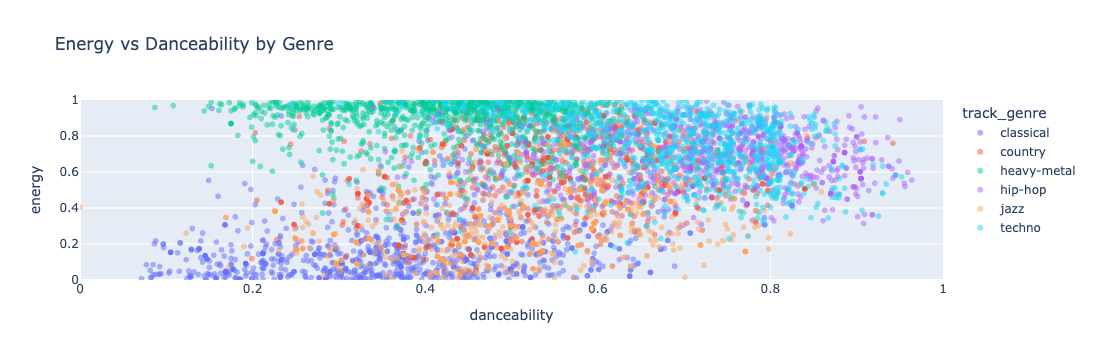

In [152]:

plot_df = df[df['track_genre'].isin(genres)].copy()

fig = px.scatter(
    plot_df,
    x='danceability',
    y='energy',
    color='track_genre',
    hover_data=['track_id'],
    opacity=0.5,
    title='Energy vs Danceability by Genre'
)

fig.update_layout(
    xaxis_range=[0, 1],
    yaxis_range=[0, 1]
)

fig.show()


### Interpretation (Energy vs. Danceability)

From the scatter plot, I can see that different music genres have different patterns when comparing energy and danceability.

**Heavy-metal and punk** tend to have high energy values, with many songs close to 1. However, their danceability varies, and the two genres overlap quite a lot.

**Hip-hop** generally has higher danceability, with many songs between 0.6 and 0.9. The energy values also tend to be relatively high, although they vary between songs.

**Classical music** has a wider range of energy values. Many classical songs have low energy, but some are also highly energetic. Most classical songs have lower danceability compared to hip-hop.

What I find interesting is that the genres are not completely separated. Some songs from different genres have similar energy and danceability values.

This tells me that these two features may help distinguish certain genres, but they are probably not enough on their own to classify every song correctly.

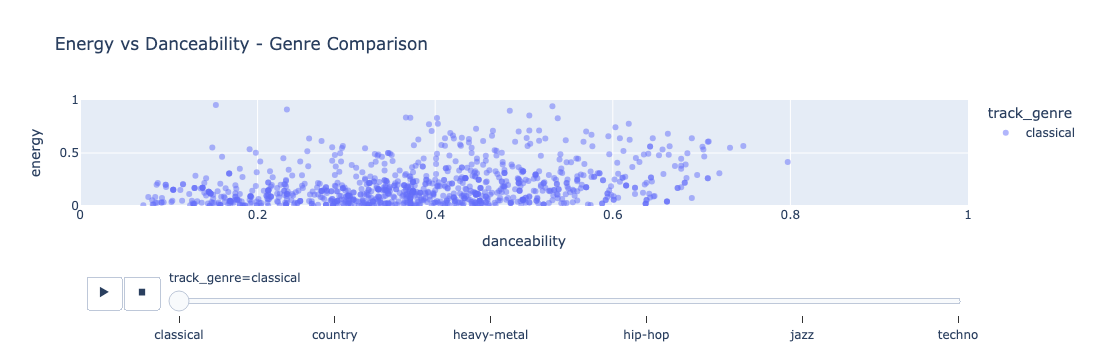

In [153]:

fig = px.scatter(
    plot_df,
    x='danceability',
    y='energy',
    color='track_genre',
    animation_frame='track_genre',
    range_x=[0, 1],
    range_y=[0, 1],
    opacity=0.5,
    title='Energy vs Danceability - Genre Comparison'
)

fig.show()


## Keeping only the six chosen genres

From here on, the analysis only uses the six genres I chose.



In [154]:
# Keep only the six chosen genres
df = df[df['track_genre'].isin(genres)]

print(f"Rows left: {len(df)}")
print(df['track_genre'].value_counts())

Rows left: 6000
track_genre
classical      1000
country        1000
heavy-metal    1000
hip-hop        1000
jazz           1000
techno         1000
Name: count, dtype: int64


### Interpretation

From the results, I can see that my dataset has been reduced from 114,000 to 6,000 rows.

Each of the six genres still contains exactly 1,000 rows, which means the dataset is still balanced between the different classes.

This is important because no genre has more rows than the others, so the model will not be biased toward a genre simply because it appears more often in the training data.

Now I have a smaller dataset with six different genres, and I can continue with the preprocessing before training my models.

However, I still need to remember that some songs appear in more than one genre, so 6,000 rows does not necessarily mean 6,000 unique songs.

In [155]:
# Re-check the problems found earlier, now only for the six genres
# We found missing values, duplicates and zero tempos earlier.
# Now I want to check if these problems still exist after keeping only six genres.
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Exact duplicate rows: {df.drop(columns='Unnamed: 0').duplicated().sum()}")
print(f"Unique songs: {df['track_id'].nunique()} out of {len(df)} rows")
print(f"Songs with tempo 0: {(df['tempo'] == 0).sum()}")
print(f"Songs with time_signature 0: {(df['time_signature'] == 0).sum()}")

Missing values: 0
Exact duplicate rows: 79
Unique songs: 5910 out of 6000 rows
Songs with tempo 0: 1
Songs with time_signature 0: 1


### Interpretation

Most of the problems from earlier are gone. There are no missing values anymore, since the broken row belonged to a genre I removed.

Some problems are still there, but they are small. There are 79 exact duplicate rows, and 11 songs are listed under two of the six genres. This matches what I found earlier when comparing the genres, where classical and jazz shared 10 songs, while jazz and techno shared 1 song.

Out of the 6,000 rows, there are 5,910 unique songs, meaning 90 rows are repeated. I also found one song with a tempo of 0 and one with a time signature of 0. These might be the same song, and it could mean that Spotify was unable to detect a clear beat or time signature.

Even though there are only a few problems left, I will handle them during preprocessing. The main reason is that duplicates could end up in both the training and test data, or in different folds during cross-validation. This means the model might be tested on a song it has already seen during training.

For example, if the model has already learned the audio features of a song during training, recognizing the same song in the test data could become easier. This could make evaluation metrics such as **accuracy, precision, recall and F1-score** look better than they really are, because the model is not being tested entirely on unseen songs.

By cleaning these problems before splitting the dataset, I can reduce the risk of data leakage and make sure the evaluation gives a more realistic picture of how well the model can classify new songs.

## Distributions: Histograms

Here I look at how the values of each audio feature are spread out across all songs.

array([[<Axes: title={'center': 'Unnamed: 0'}>,
        <Axes: title={'center': 'popularity'}>,
        <Axes: title={'center': 'duration_ms'}>,
        <Axes: title={'center': 'danceability'}>],
       [<Axes: title={'center': 'energy'}>,
        <Axes: title={'center': 'key'}>,
        <Axes: title={'center': 'loudness'}>,
        <Axes: title={'center': 'mode'}>],
       [<Axes: title={'center': 'speechiness'}>,
        <Axes: title={'center': 'acousticness'}>,
        <Axes: title={'center': 'instrumentalness'}>,
        <Axes: title={'center': 'liveness'}>],
       [<Axes: title={'center': 'valence'}>,
        <Axes: title={'center': 'tempo'}>,
        <Axes: title={'center': 'time_signature'}>, <Axes: >]],
      dtype=object)

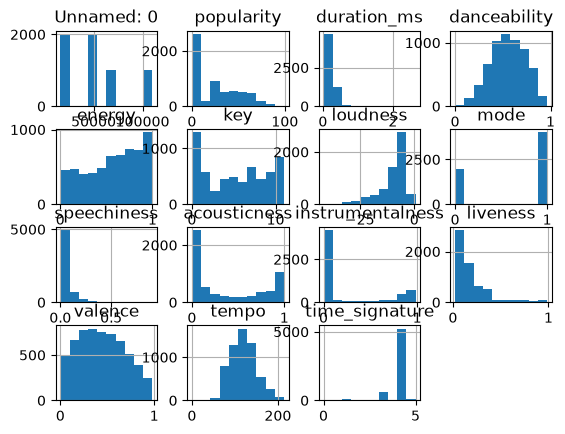

In [156]:
df.hist()

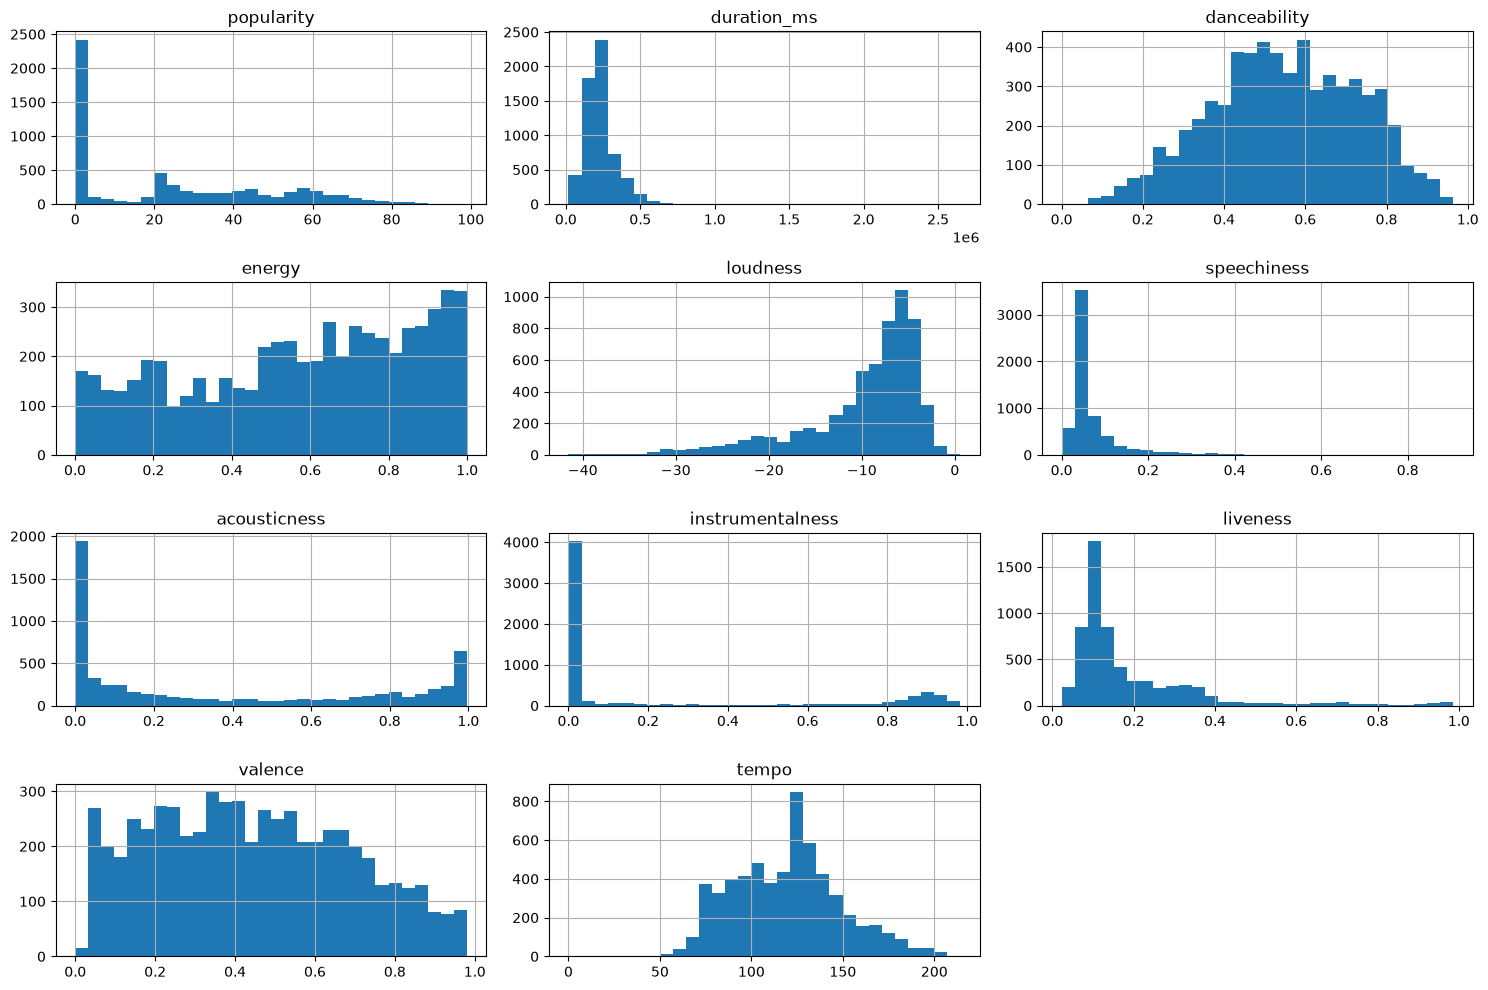

In [157]:
# Histograms of the audio features
features = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

df[features].hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

### Interpretation

From the histograms, I can see that the audio features are spread out in different ways.

Some features, like `danceability`, `tempo` and `valence`, look roughly bell-shaped. This means 
most songs are somewhere in the middle, and only a few songs have very low or very high values.

Other features are skewed. `speechiness`, `liveness` and `duration_ms` are right-skewed, which 
means most songs have low values, while a small group of songs has much higher values. 
`loudness` and `energy` are the opposite. Here most songs are loud and energetic, and only a 
few songs are very quiet or calm.

The most interesting ones are `acousticness` and `instrumentalness`, because they have two peaks 
instead of one. For `acousticness`, many songs are close to 0 and many are close to 1. This tells 
me there are two groups of songs: some are made with acoustic instruments, and some are more 
electronic. `instrumentalness` shows something similar, where most songs have vocals, but one group 
has almost no vocals at all. Since my goal is to separate genres, I think these two features could 
be very useful, because they seem to split the songs into clear groups.

I decided not to change the skewed features right now. Tree-based models like Decision Tree and 
Random Forest are not affected by the shape of the data, because they only look for a value to 
split on. KNN and neural networks are more sensitive to the size of the values, so I will scale 
the features in preprocessing. I might also test a log transform on the skewed features as one 
of my processing alternatives, and let the tuning show if it actually helps.


I left out `key`, `mode` and `time_signature` because they represent categories rather than continuous measurements. For example, `key` represents musical notes, while `mode` tells us whether a song is in major or minor. A histogram of these values would show how often each category appears, rather than how a continuous feature is distributed.

I also left out `Unnamed: 0` because it is just a row number and does not tell us anything useful about the songs.

I will look at the categorical features separately later, since they need to be interpreted differently.

In [158]:
# near 0 = symmetric, positive = right tail, negative = left tail

# Skewness is a statistical measure that describes the degree of asymmetry in a probability distribution. It gives insight into how the data is distributed around the mean, and can be useful for understanding underlying patterns and properties in the dataset. A skewness near 0 indicates a symmetric distribution, while positive skewness indicates a longer right tail and negative skewness indicates a longer left tail.
# It is important to note that skewness does not give information about the distribution of the data, but only about the asymmetry. For example, two datasets can have the same skewness, but different distributions. Therefore skewness should be used together with other statistical measures and visualizations to get a more complete understanding of the dataset.
# skewness can be useful for identifying potential problems with the data, for example skewness in the distribution of a variable that can affect the results of a statistical analysis. It can also be used to identify potential transformations of the data that can improve normality and reduce skewness.

print("Skewness per column:")
print(df.select_dtypes(include='number').skew().round(3).to_string())

Skewness per column:
Unnamed: 0          0.630
popularity          0.568
duration_ms         5.005
danceability       -0.134
energy             -0.348
key                -0.001
loudness           -1.638
mode               -0.714
speechiness         4.300
acousticness        0.486
instrumentalness    1.173
liveness            2.463
valence             0.203
tempo               0.275
time_signature     -3.508


In [159]:
# How many songs have popularity 0, and which genres are they from?
print(f"Songs with popularity 0: {(df['popularity'] == 0).sum()}")
print(df[df['popularity'] == 0]['track_genre'].value_counts())

Songs with popularity 0: 2029
track_genre
jazz           681
country        587
classical      398
hip-hop        289
techno          72
heavy-metal      2
Name: count, dtype: int64


### Interpretation

2029 songs have a popularity of 0. That is about one third of all the songs in my six genres, 
which is a lot.

What stands out is that the zeros are not spread evenly between the genres. Jazz has 681 songs 
with popularity 0, which is more than two thirds of all the jazz songs. Country and classical 
also have many. Heavy metal, on the other hand, only has 2.

A popularity of 0 most likely means that a song has very few or no recent plays on Spotify. 
It says something about how many people listen to the song, not about how the song sounds.

This is a problem for my goal. If I keep `popularity`, the model could learn a shortcut like 
"if popularity is 0, the song is probably jazz or country". That might help the accuracy, but 
it doesn't teach the model anything about what makes a genre sound the way it does. And it 
would not work for a new jazz song that happens to be popular.

Because of this, I am leaning towards dropping `popularity`. Since the assignment asks for 
multiple processing alternatives, I will test both keeping and dropping it in preprocessing, 
and compare the results.

##  Outliers

Here I look for songs with values that are far away from the rest. These could be errors in 
the data, or just unusual songs.

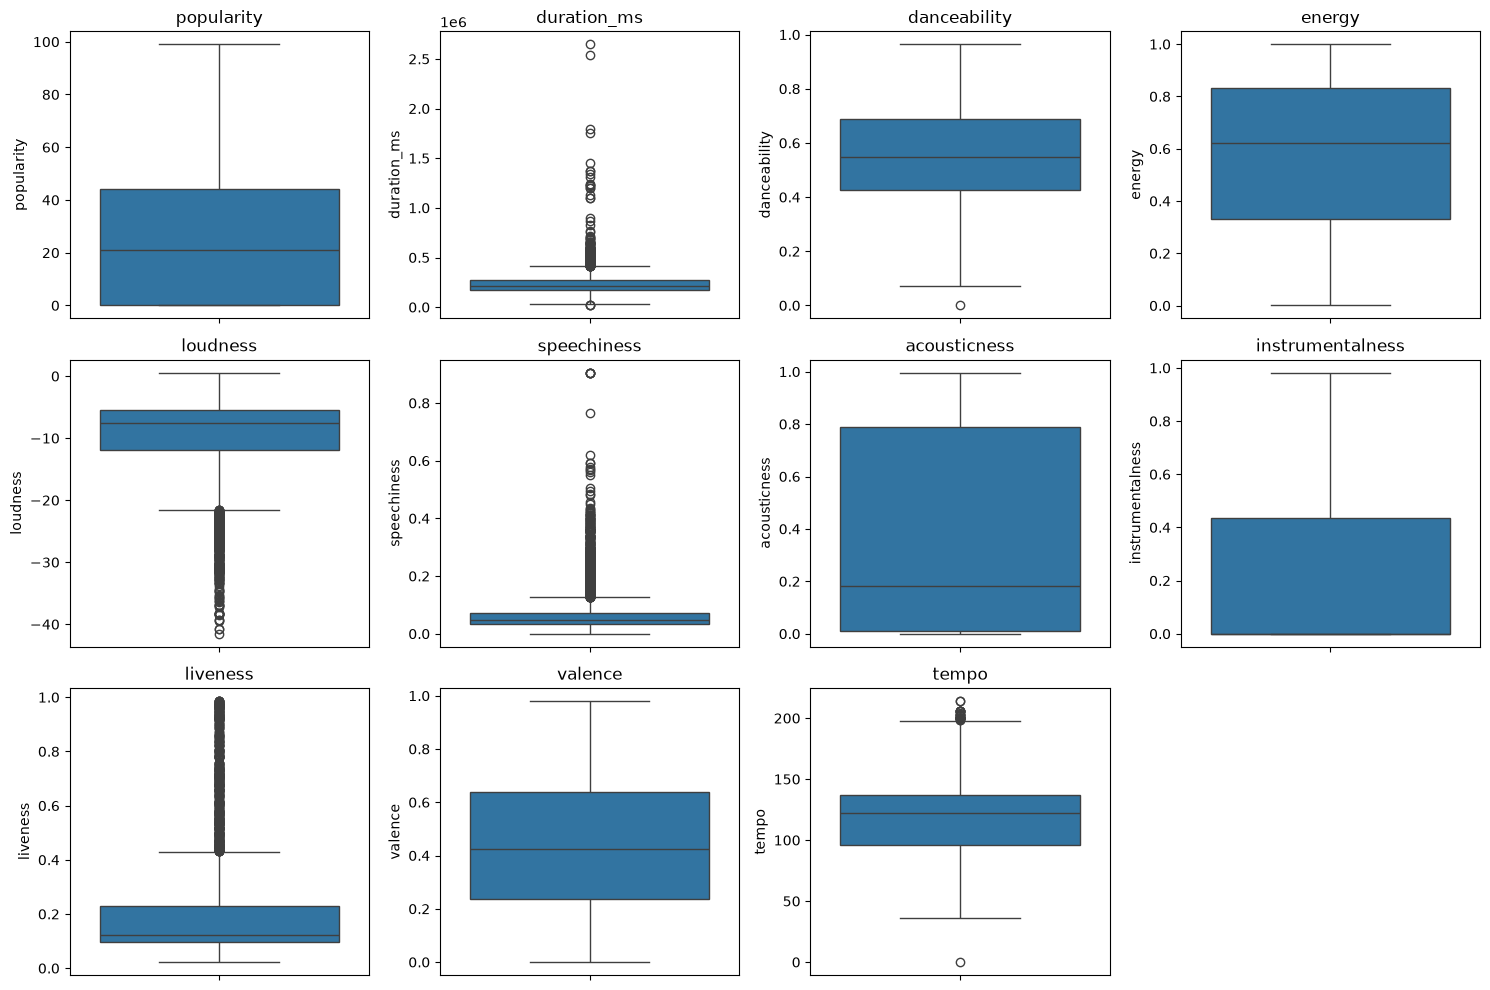

In [160]:
# Box plots of the audio features
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)

# Hide the empty 12th plot, since there are only 11 features
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

## Outliers 

In [161]:
# Checking exactly how many outliers there are in each  column using the IQR method (Interquartile Range).
for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    if n_outliers > 0:
        print(f"  {col}: {n_outliers} outliers")
    else:
        print(f"  {col}: no outliers")

  popularity: no outliers
  duration_ms: 382 outliers
  danceability: 1 outliers
  energy: no outliers
  loudness: 442 outliers
  speechiness: 638 outliers
  acousticness: no outliers
  instrumentalness: no outliers
  liveness: 411 outliers
  valence: no outliers
  tempo: 29 outliers


### Interpretation

The features with the most outliers are `speechiness`, `loudness`, `liveness` and `duration_ms`. 
These are the same features that looked skewed in the histograms, so this was expected.

I decided to keep these outliers, because they look like real songs and not errors. 
For example, hip-hop has a lot of rapping, so many hip-hop songs will have a high 
`speechiness`. If I removed these as outliers, I would remove part of what makes hip-hop 
sound different from the other genres, which is exactly what I want the model to learn. 
In the same way, very quiet songs are probably classical or jazz, and the longest songs, 
around 44 minutes, are most likely long classical pieces. Some songs also have a high 
`liveness` because they were recorded live with an audience.

The only outlier I don't trust is the song with a tempo of 0, which also shows up as an outlier 
in `danceability`. This is the song where Spotify couldn't measure a beat, which I found earlier. 
I will remove it in preprocessing.

##  Correlation 
Here i check wich features are related to each other. If two features are very strong they give the model almost the same ifnormation


- Website for reference: https://lost-stats.github.io/Presentation/Figures/heatmap_colored_correlation_matrix.html


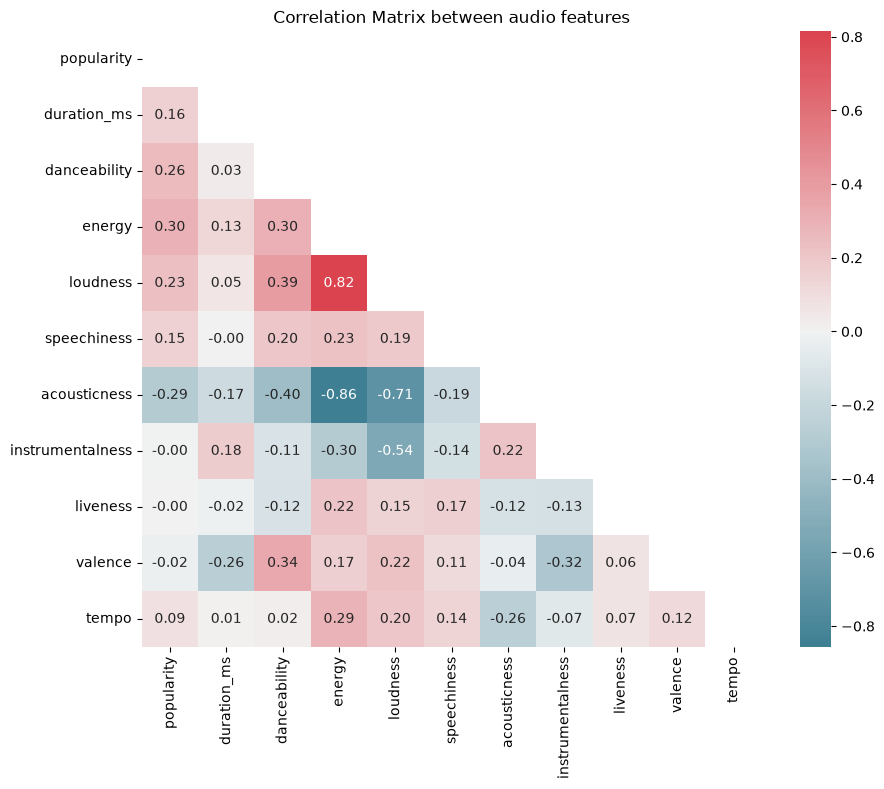

In [162]:
# Correlation between the audio features 

corr = df[features].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(220, 10, as_cmap=True)


plt.figure(figsize=(10,8))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',cmap=cmap,center=0)

plt.title('Correlation Matrix between audio features')

plt.show()

### Interpretation

Setting a threshold: 
- A common rule is: if two features correlate above 0.8 (or below -0.8), they carry almost the same information, and you can consider dropping one. Nothing here goes above 0.8. The highest is 0.76, so you keep all features.
The strongest relationship is between `energy` and `loudness` (0.76). This makes sense, since 

loud songs usually feel energetic. `acousticness` has a strong negative relationship with 
`energy` (-0.73), and a moderate negative one with `loudness` (-0.59). This means acoustic songs, 
like classical or jazz played on real instruments, tend to be calmer and quieter, while electronic 
or heavy songs tend to be louder and more energetic.

There is also a moderate relationship between `valence` and `danceability` (0.48), so happy-sounding 
songs tend to be more danceable. `instrumentalness` is negatively related to `loudness` (-0.43) and 
`valence` (-0.32), so songs without vocals tend to be quieter and sound less happy.



`popularity' has almost no correlation with the other audio features, with values between -0.10 and 0.05. This supports what I found earlier, where 2,029 songs had a popularity score of 0, but the number varied a lot between genres. For example, jazz had 681 songs with popularity 0, while heavy-metal had only 2.

This tells me that popularity differs between genres, but it has very little linear relationship with the audio features. Since popularity measures how popular a song is rather than how it sounds, I don't want the model to use it as a shortcut when predicting genres. Therefore, I will exclude `popularity` from the training features.

**My decision:**
I use a threshold of 0.8. If two features correlate more strongly than that, they give the model 
almost the same information, and I would consider dropping one of them. Since no pair goes above 0.8, 
I keep all the features. Even `energy` and `loudness` measure different things: a song can be loud 
without feeling energetic, for example a slow but loud orchestral piece.

## Features vs genre 

Here I compare each audio feature across the six genres. If a feature has very differnt values for different genres, it should be usefull for telling them apart.

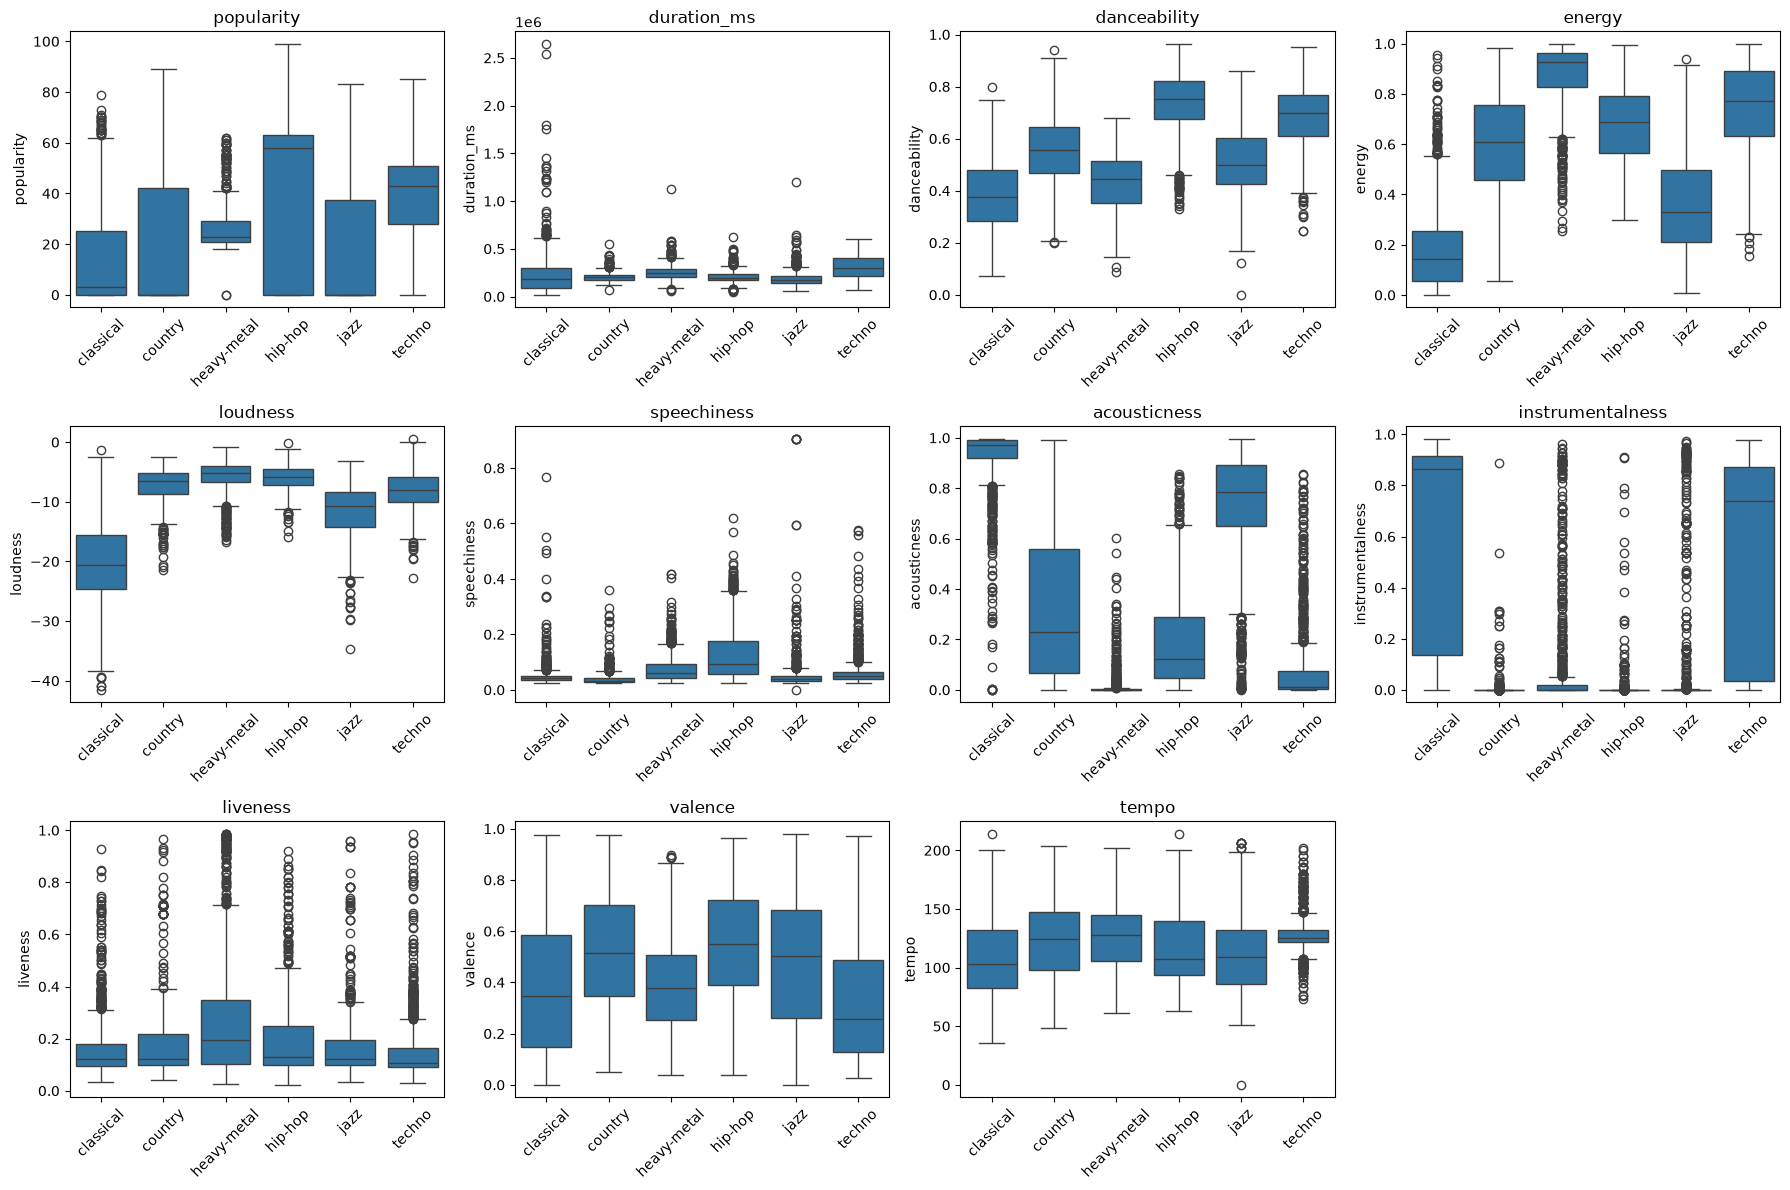

In [163]:
# Box plots of each feature, split by genre
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=df, x='track_genre', y=col, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

# Hiding the empty 12th plot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Interpretation

This plot shows clear differences between the genres.

Classical is very quiet and calm, almost fully acoustic, and most songs have no vocals. 
Heavy-metal is the opposite: it is the most energetic and loudest genre, and not acoustic 
at all. Hip-hop is the most danceable genre and has the most speech, which makes sense because 
of the rapping. Techno is energetic and danceable, often without vocals, and almost all 
techno songs have a very similar tempo. Jazz is calm and acoustic like classical, while 
country sits somewhere in the middle on most features.

The features that separate the genres best are `acousticness`, `energy`, `loudness`, 
`instrumentalness` and `danceability`, because the boxes for the different genres are at very 
different heights. `speechiness` mostly helps to recognise hip-hop, and `tempo` mostly helps to 
recognise techno. `liveness` and `duration_ms` look almost the same for every genre, so they 
probably won't help much.

What I find most interesting is how similar genres can still be told apart. Classical and jazz 
are both calm and acoustic, but classical usually has no vocals while jazz does. Heavy-metal and 
techno are both energetic, but techno is more danceable and has fewer vocals. This tells me that 
no single feature can separate all the genres on its own. The models will need to combine several 
features to tell them apart.

## categorical features 

`explicit`, `mode`, `time_signature` and `key` are categories, not amounts. Here I check how often 
each category appears in each genre, to see if they could help tell the genres apart.

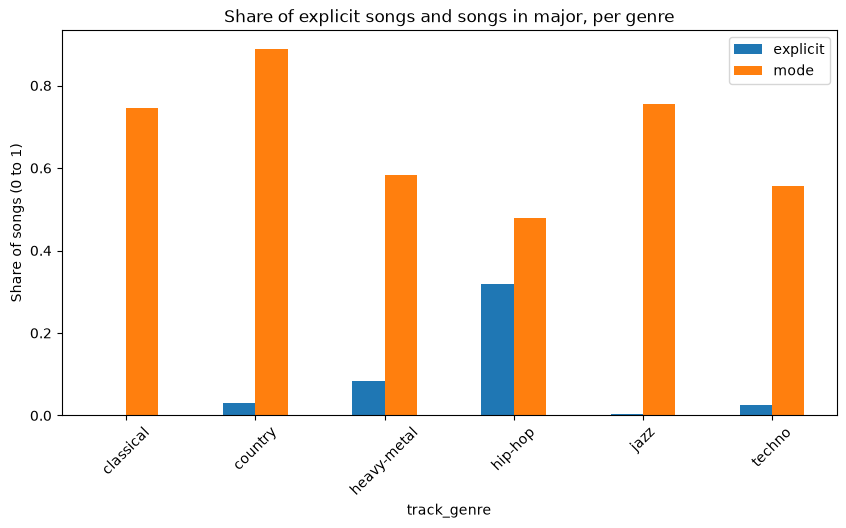

In [164]:
# Share of explicit songs and songs in major, for each genre
share = df.groupby('track_genre')[['explicit', 'mode']].mean()

share.plot(kind='bar', figsize=(10, 5))
plt.title('Share of explicit songs and songs in major, per genre')
plt.ylabel('Share of songs (0 to 1)')
plt.xticks(rotation=45)
plt.show()

### Interpretation

Hip-hop is the only genre with a lot of explicit songs, about 32%. The other genres have very 
few, and classical and jazz have almost none. This means `explicit` can help the model recognise 
hip-hop, but it won't help much to tell the other genres apart.

For `mode`, country has the most songs in major, close to 90%, while hip-hop is about half major 
and half minor. Classical and jazz are mostly in major too, while heavy-metal and techno are more 
mixed. There are some differences, but they are not as big as for features like `acousticness` 
or `energy`.

In [165]:
# How many songs in each genre have each time signature
pd.crosstab(df['track_genre'],df['time_signature'])

time_signature,0,1,3,4,5
track_genre,,,,,
classical,0,42,226,691,41
country,0,1,116,877,6
heavy-metal,0,3,47,945,5
hip-hop,0,11,23,948,18
jazz,1,17,144,807,31
techno,0,3,26,969,2


### Interpretation

Almost every song in every genre has a time signature of 4, which is the most common rhythm in 
music. The main exception is classical and jazz, which have more songs in 3 than the other genres 
(226 and 144). This is the rhythm used in waltzes. Classical also has more songs in 1 and 5, 
which are unusual rhythms.

This means `time_signature` can help a little to recognise classical and jazz, but for the 
other genres it is almost always 4.

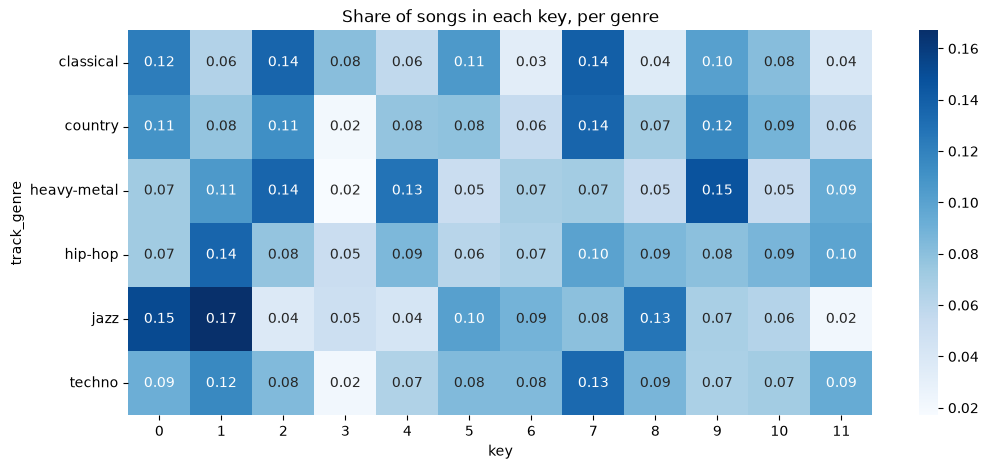

In [166]:
# Share of songs in each key, for each genre
key_share = pd.crosstab(df['track_genre'], df['key'], normalize='index')

plt.figure(figsize=(12, 5))
sns.heatmap(key_share, annot=True, fmt='.2f', cmap='Blues')
plt.title('Share of songs in each key, per genre')
plt.show()

### Interpretation

If songs were spread completely evenly across the 12 keys, each square would be about 0.08, 
since 1 divided by 12 is about 0.08.

Most squares are close to that, but some genres lean towards certain keys. Jazz has more songs 
in key 0 and key 1 (0.15 and 0.17) and very few in key 11 (0.02). Heavy-metal has more songs in 
key 9 (0.15) and key 2 (0.14). Key 3 is rare in almost every genre.

So `key` shows some differences between the genres, but they are smaller than for the audio 
features. It might help the model a little, together with the other features.

### Exploring musical key and time signature

I wanted to investigate whether musical key and time signature could help distinguish the six genres I selected.

First, I compared the time signatures across the genres. I noticed that most songs use time signature 4, especially in techno, hip-hop and heavy-metal. Classical and jazz have more songs using time signature 3 compared to the other genres.

Next, I looked at the distribution of musical keys. I used percentages instead of counts to make the genres easier to compare. The heatmap shows some differences, but the genres also share many of the same keys.

From these results, I think both features might provide some useful information, but neither seems strong enough to separate the genres on its own.

## EDA summary

### What I found

**The dataset**
The full dataset has 114,000 songs across 114 genres, with 1,000 songs in each genre. Many genres 
share songs. For example, singer-songwriter and songwriter share all 1,000 songs, and pairs like 
punk / punk-rock share more than half. A model can't separate genres that contain the same songs, 
so I chose six genres that share almost no songs: classical, country, heavy-metal, hip-hop, jazz 
and techno. This gives 6,000 songs, still perfectly balanced, so a random guess would be right 
about 17% of the time.

**Data quality**
In the six genres there are no missing values. There are 79 exact duplicate rows, and 11 songs 
are listed under two of my genres. One song has a tempo and time signature of 0, which means 
Spotify couldn't measure its beat.

**The features**
The features that separate the genres best are `acousticness`, `energy`, `loudness`, 
`instrumentalness` and `danceability`. `speechiness` and `explicit` mostly help to recognise 
hip-hop, and `tempo` mostly helps to recognise techno. `time_signature` helps a little for 
classical and jazz. `liveness` and `duration_ms` look almost the same for every genre.

No single feature separates all six genres. For example, classical and jazz are both calm and 
acoustic, but classical usually has no vocals while jazz does. The models will need to combine 
several features.

`popularity` has no relationship with any of the audio features, and a third of the songs have a 
popularity of 0, mostly in jazz, country and classical. It says something about listeners, not 
about how a song sounds.

### My decisions for preprocessing

| What | Decision | Why |
|---|---|---|
| `Unnamed: 0`, `track_id` | Drop | Just a row number and an ID, they say nothing about the music. I use `track_id` to find duplicates first |
| `artists`, `album_name`, `track_name` | Drop | Names, not sound. They could let the model learn who made a song instead of how it sounds |
| Exact duplicates | Remove | They could end up in both training and test data |
| Songs in two genres | Remove | The same song with two different labels confuses the model |
| Song with tempo 0 | Remove | The value is missing, not real |
| Outliers | Keep | They are real songs, and they are often what makes a genre different |
| `popularity` | Test both keeping and dropping | It may help accuracy, but it is not about the sound |
| Skewed features | Test with and without a log transform | Some models are sensitive to skew, others are not |
| Correlated features | Keep all | No pair goes above my threshold of 0.8 |
| `explicit` | Turn into 1/0 | It is True/False |
| `key`, `time_signature` | Treat as categories | A higher number does not mean "more" |
| Scaling | Test different scalers | KNN and neural networks need features on the same scale |


**Scaling:** Some numerical features have very different ranges. For example, energy ranges from 0 to 1, while duration is measured in thousands of milliseconds. This can affect distance-based models such as KNN, so I will test scaling the numerical features during preprocessing. I will compare the results to see which approach works best.

# PREPROCESSING

In this part I carry out the decisions from the EDA summary. First I clean the data, 
then I prepare the features and the label for the models.

##  Cleaning

In [167]:
# Drop the row number column first. It makes every row unique, so duplicates can't be found while it's there.
# errors='ignore' means: if the column is already gone, just continue instead of crashing.
df = df.drop(columns='Unnamed: 0', errors='ignore')

# Remove exact duplicate rows
df = df.drop_duplicates()
print(f"Rows after removing exact duplicates: {len(df)}")

Rows after removing exact duplicates: 5921


In [168]:
# Find songs that are listed under more than one genre
genres_per_song = df.groupby('track_id')['track_genre'].nunique()
songs_in_two_genres = genres_per_song[genres_per_song > 1].index

# Remove all copies of those songs, since we can't know which genre is the right one
df = df[~df['track_id'].isin(songs_in_two_genres)]
print(f"Songs listed under two genres: {len(songs_in_two_genres)}")
print(f"Rows left: {len(df)}")

Songs listed under two genres: 11
Rows left: 5899


In [169]:
# Remove songs where Spotify couldn't measure a tempo
df = df[df['tempo'] != 0]
print(f"Rows left: {len(df)}")
print(df['track_genre'].value_counts())

Rows left: 5898
track_genre
country        1000
techno          999
heavy-metal     998
hip-hop         991
jazz            987
classical       923
Name: count, dtype: int64


### Interpretation

After cleaning, 5,898 songs are left. I removed the exact duplicates, the songs listed under two 
genres, and the song with a tempo of 0.

Classical lost the most songs and now has 923, while the other genres still have close to 1,000. 
This is because most of the duplicates were classical songs, and classical also shared some songs 
with jazz.

The genres are still fairly balanced, since classical has more than 90% as many songs as the 
biggest genre. To keep it fair, I will use a stratified split, so every genre has the same share 
in the training and test data. I will also use the macro average for precision, recall and F1, 
which gives every genre the same weight.

##  Dropping columns

Here I drop the columns that don't describe how a song sounds.

In [170]:
# Drop columns that are names or IDs, not audio features.
# track_id is dropped now, since I'm done using it to find duplicates.
df = df.drop(columns=['track_id', 'artists', 'album_name', 'track_name'])

print(f"Columns left: {list(df.columns)}")

Columns left: ['popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


## Encoding

Models need numbers. Here I turn `explicit` into numbers, and separate the features from the label.

In [171]:
# explicit is True/False. Turn it into 1/0 so the models can use it.
df['explicit'] = df['explicit'].astype(int)
print(df['explicit'].value_counts())

explicit
0    5442
1     456
Name: count, dtype: int64


In [172]:
# Separate the features (input) from the label (what we want to predict)
features = df.drop(columns='track_genre')
targets = df['track_genre']

print(f"Features: {features.shape[1]} columns")
print(f"Targets: {targets.nunique()} genres")

Features: 15 columns
Targets: 6 genres


In [173]:
# Turn the genre names into numbers 0 to 5
label_encoder = LabelEncoder()
targets = pd.Series(label_encoder.fit_transform(df['track_genre']), index=df.index)

# Show which number belongs to which genre
for number, genre in enumerate(label_encoder.classes_):
    print(f"{number} = {genre}")

0 = classical
1 = country
2 = heavy-metal
3 = hip-hop
4 = jazz
5 = techno


### Interpretation

`explicit` is now 1/0 instead of True/False. The genre names are turned into numbers from 0 to 5 
with `LabelEncoder`. The numbers are just labels and don't mean that one genre is "more" than 
another. I keep the encoder so I can turn the numbers back into genre names later, for example 
on the confusion matrices.

I don't encode `key` and `time_signature` here, because I want to test two ways of handling them. 
That choice is part of the pipeline later.

## Train/test split

I split the data into a training set and a test set. The models learn from the training set, 
and the test set is only used once at the very end, to see how well they do on songs they have 
never seen.

Unlike in my first project, I don't need a separate validation set. The hyperparameter tuning uses 
cross-validation, which creates its own validation folds from the training data.

In [174]:
# Stratified split: 80% train, 20% test.
# Sampling 80% from each genre separately keeps the same share of every genre in both sets.

random_state = 42

train_indices = df.groupby('track_genre').sample(frac=0.8, random_state=random_state).index
train_features = features.loc[train_indices]
train_targets = targets.loc[train_indices]

# The test set is everything that wasn't picked for training
test_indices = df.drop(train_indices).index
test_features = features.loc[test_indices]
test_targets = targets.loc[test_indices]

# Checking that the distribution is the same in both sets
print("Train:")

print(train_targets.value_counts() / train_targets.count())
print("\nTest:")
print(test_targets.value_counts() / test_targets.count())

Train:
1    0.169563
5    0.169351
2    0.169139
3    0.168080
4    0.167444
0    0.156422
Name: count, dtype: float64

Test:
1    0.169492
2    0.169492
5    0.169492
3    0.167797
4    0.166949
0    0.156780
Name: count, dtype: float64


### Interpretation

The data is split into 80% training and 20% test data. Each genre has almost exactly the same 
share in both sets, so the split is stratified as intended. Classical (0) has a slightly smaller 
share than the other genres in both sets, about 15.6%, because it lost the most songs during 
cleaning.

This means the test set is a fair representation of the training set, and no genre is over- or 
under-represented when I evaluate the models.

##  Pipeline and processing alternatives

Instead of choosing one way to process the data, I set up several alternatives and let the 
automated tuning compare them. I use a `Pipeline` with a `ColumnTransformer`, following the 
approach from the course workshop.

A pipeline also prevents data leakage. During cross-validation, the processing (for example the 
scaling) is learned only from the training folds, and then applied to the validation fold.

The alternatives come from my EDA:
- **Skewed features:** with or without a `PowerTransformer` (Yeo-Johnson)
- **Scaling:** no scaling, `StandardScaler` or `MinMaxScaler`
- **popularity:** keep or drop
- **key and time_signature:** one-hot encoding or keep them as numbers

In [175]:
# Group the columns by how they should be processed
numeric_features = ['duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
                    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

categorical_features = ['key', 'time_signature']
binary_features = ['explicit', 'mode']

## Preprocessor

The preprocessor describes how each group of columns is processed before the model sees it. 
Before this step I only did things that follow a fixed rule and don't depend on the data: 
cleaning, `explicit` to 1/0 and the genre label. Everything that learns from the data 
(scaling, power transform, one-hot encoding) is defined here.

Nothing is processed yet. This only defines the steps. The values are calculated when the pipeline 
is fitted inside `GridSearchCV`, so the mean and standard deviation come from the training folds only.
I make it a function so every model gets its own fresh copy.

`StandardScaler` subtracts the mean and divides by the standard deviation for each column, the same 
formula as the mean normalization in my first project. KNN and neural networks need it. Trees don't.

In [176]:
# Build the preprocessing step. Each part below is a default, and the grid search can swap it 
# for an alternative.

# Why do we make a preprocessor? , what did we before this 
# What is preprocessor ? 
#what is a standardscaler how do we  use when do we use and what is it for 
# We dont normalize data right here 
def make_preprocessor():
    return ColumnTransformer([
        # Numeric features: first an optional power transform, then scaling
        ('numeric', Pipeline([
            ('power', 'passthrough'),
            ('scale', StandardScaler())
        ]), numeric_features),

        # popularity on its own, so it can be kept (scaled) or dropped
        ('popularity', StandardScaler(), ['popularity']),

        # key and time_signature: one-hot encoded by default.
        # handle_unknown='ignore' avoids errors if a rare value only appears in one fold
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),

        # explicit and mode are already 0/1
        ('binary', 'passthrough', binary_features)
    ])

# MODELS

I train two baseline models, three ensemble models and two neural networks. Each model is tuned 
with `GridSearchCV`, which uses 5-fold cross-validation on the training data. I use the macro F1 
score to compare settings, so every genre counts equally.

After tuning, `GridSearchCV` automatically refits the best settings on the whole training set. 
Then I test each model once on the test set.

In [177]:
# Stores the test results of every model, so they can be compared at the end
results = {}

# Extra metrics: specificity and NPV, the "mirror image" of recall and precision.
# With six genres there is no single negative class, so each genre is compared against all
# the other genres (one-vs-rest), and the results are averaged over the six genres.
def extra_metrics(y_true, y_pred):
    matrices = multilabel_confusion_matrix(y_true, y_pred)   # one 2x2 matrix per genre
    specificities, npvs = [], []
    for matrix in matrices:
        tn, fp, fn, tp = matrix.ravel()
        specificities.append(tn / (tn + fp) if (tn + fp) > 0 else 0)
        npvs.append(tn / (tn + fn) if (tn + fn) > 0 else 0)
    return np.mean(specificities), np.mean(npvs)


# Used for final testing.
# average='macro' calculates each metric per genre and takes the average, so every genre counts equally.
def test(model):
    train_predictions = model.predict(train_features)
    test_predictions = model.predict(test_features)
    spec, npv = extra_metrics(test_targets, test_predictions)

    print(f'Training Accuracy: {accuracy_score(train_targets, train_predictions):.2f} Testing: {accuracy_score(test_targets, test_predictions):.2f}')
    print(f'Training Precision: {precision_score(train_targets, train_predictions, average="macro"):.2f} Testing: {precision_score(test_targets, test_predictions, average="macro"):.2f}')
    print(f'Training Recall: {recall_score(train_targets, train_predictions, average="macro"):.2f} Testing: {recall_score(test_targets, test_predictions, average="macro"):.2f}')
    print(f'Training F1: {f1_score(train_targets, train_predictions, average="macro"):.2f} Testing: {f1_score(test_targets, test_predictions, average="macro"):.2f}')
    print(f'Specificity (TNR) - Testing: {spec:.2f}')
    print(f'NPV               - Testing: {npv:.2f}')

    return {
        'accuracy': accuracy_score(test_targets, test_predictions),
        'precision': precision_score(test_targets, test_predictions, average='macro'),
        'recall': recall_score(test_targets, test_predictions, average='macro'),
        'f1': f1_score(test_targets, test_predictions, average='macro'),
        'specificity': spec,
        'npv': npv
    }

In [178]:
# Trains a new model n_runs times with the same settings and takes the average of the scores on the validation set.
# This is used for all the tuning, so the best setting is found from the average and not from one single run.
def average_validation(model_class, params, n_runs=5):
    accs, precs, recs, f1s, specs = [], [], [], [], []
    for _ in range(n_runs):
        model = model_class(**params)  # no random_state here
        model.fit(train_features, train_targets)
        pred = model.predict(validation_features)
        accs.append(accuracy_score(validation_targets, pred))
        precs.append(precision_score(validation_targets, pred))
        recs.append(recall_score(validation_targets, pred))
        f1s.append(f1_score(validation_targets, pred))
        specs.append(extra_metrics(validation_targets, pred)[0])


        
    print(f"Avg over {n_runs} runs: Accuracy: {np.mean(accs):.3f}, "
          f"Precision: {np.mean(precs):.3f}, Recall: {np.mean(recs):.3f}, F1: {np.mean(f1s):.3f}, "
          f"Specificity: {np.mean(specs):.3f}")
    return {'accuracy': np.mean(accs), 'precision': np.mean(precs), 'recall': np.mean(recs),
            'f1': np.mean(f1s), 'specificity': np.mean(specs)}

## Baseline : Decision Tree

In [179]:
dt_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', DecisionTreeClassifier(random_state=42))
])

dt_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__max_depth': [4, 8, 12, 16, None],
    'estimator__min_samples_leaf': [1, 5, 10],
    'estimator__criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(dt_pipe, dt_params, scoring='f1_macro', n_jobs=-1)
dt_grid.fit(train_features, train_targets)

print(f"Best settings: {dt_grid.best_params_}")
print(f"Best cross-validation F1: {dt_grid.best_score_:.3f}")

Best settings: {'estimator__criterion': 'entropy', 'estimator__max_depth': 12, 'estimator__min_samples_leaf': 1, 'preprocess__categorical': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.833


The best Decision Tree reaches a macro F1 of 0.833 in cross-validation. This is far above the 
17% a random guess would get.

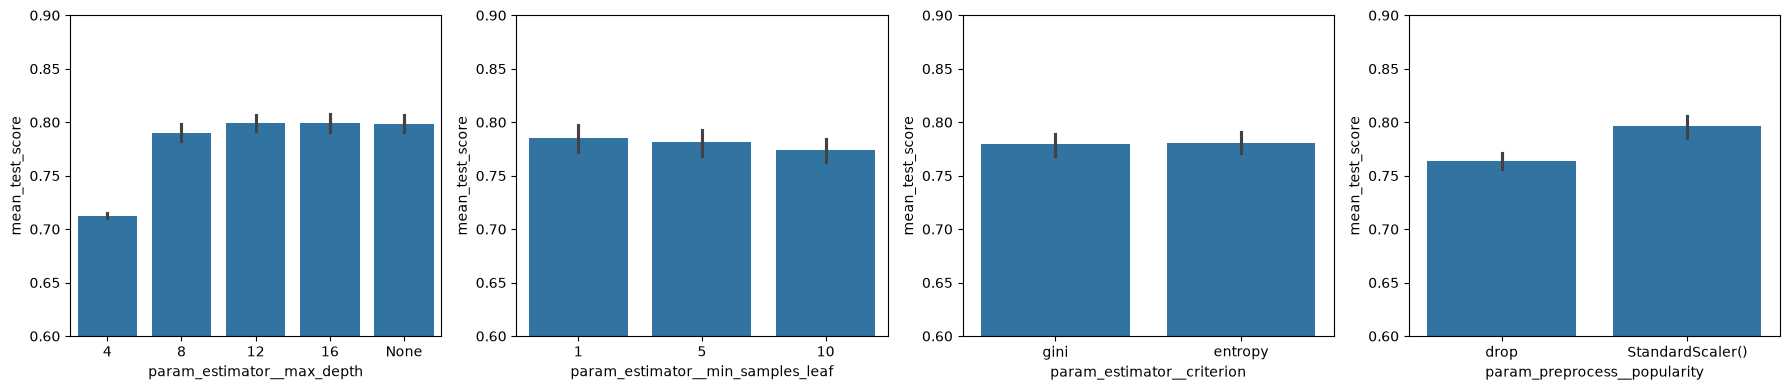

In [180]:
# Put the tuning results in a dataframe
dt_results = pd.DataFrame(dt_grid.cv_results_)

# None and the scaler object can't be plotted directly, so turn them into text
dt_results['param_estimator__max_depth'] = dt_results['param_estimator__max_depth'].fillna('None').astype(str)
dt_results['param_preprocess__popularity'] = dt_results['param_preprocess__popularity'].astype(str)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.barplot(data=dt_results, x='param_estimator__max_depth', y='mean_test_score',
            order=['4', '8', '12', '16', 'None'], ax=axes[0])
sns.barplot(data=dt_results, x='param_estimator__min_samples_leaf', y='mean_test_score', ax=axes[1])
sns.barplot(data=dt_results, x='param_estimator__criterion', y='mean_test_score', ax=axes[2])
sns.barplot(data=dt_results, x='param_preprocess__popularity', y='mean_test_score', ax=axes[3])

for ax in axes:
    ax.set_ylim(0.6, 0.9)   # zoom in so small differences are visible
plt.tight_layout()
plt.show()


### Interpretation

The best Decision Tree reaches a macro F1 of 0.833 in cross-validation and 0.843 on the test set. 
The two scores are very close, so the model does about as well on new songs as during tuning. 
It is also far above the 17% a random guess would get.

The plots show that the tested values were wide enough. For `max_depth`, the score jumps from 
depth 4 to 8 and then levels out from 12 onwards, so a deeper tree doesn't help. 
For `min_samples_leaf`, 1 works best, which is the smallest possible value. 
`gini` and `entropy` give almost the same result.

Keeping `key` and `time_signature` as numbers worked better than one-hot encoding. This makes 
sense for a tree, since it can split directly on a number, while one-hot encoding spreads `key` 
over 12 separate columns.

Keeping `popularity` gave the biggest improvement, from about 0.76 to 0.80. This matches what I 
expected in the EDA. However, I still think part of this comes from a shortcut, since jazz and 
country have many songs with popularity 0. It helps the score, but it doesn't say anything about 
how a song sounds.

## Baseline : K-Nearest Neighbors (KNN)

KNN predicts the genre of a song by looking at the most similar songs in the training data. 
Since it measures distances between songs, it is sensitive to the scale of the features. 
This is where the scaling and power transform alternatives matter most.

In [181]:

knn_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', KNeighborsClassifier())
])

knn_params = {
    # Processing alternatives
    'preprocess__numeric__power': ['passthrough', PowerTransformer()],
    'preprocess__numeric__scale': ['passthrough', StandardScaler(), MinMaxScaler()],
    'preprocess__popularity': ['drop', StandardScaler()],
    # Model parameters
    'estimator__n_neighbors': [21, 31, 51, 75, 101],
    'estimator__weights': ['uniform', 'distance'],
    'estimator__p': [1, 2]
}

knn_grid = GridSearchCV(knn_pipe, knn_params, scoring='f1_macro', n_jobs=-1)
knn_grid.fit(train_features, train_targets)

print(f"Best settings: {knn_grid.best_params_}")
print(f"Best cross-validation F1: {knn_grid.best_score_:.3f}")

Best settings: {'estimator__n_neighbors': 31, 'estimator__p': 1, 'estimator__weights': 'distance', 'preprocess__numeric__power': PowerTransformer(), 'preprocess__numeric__scale': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.851


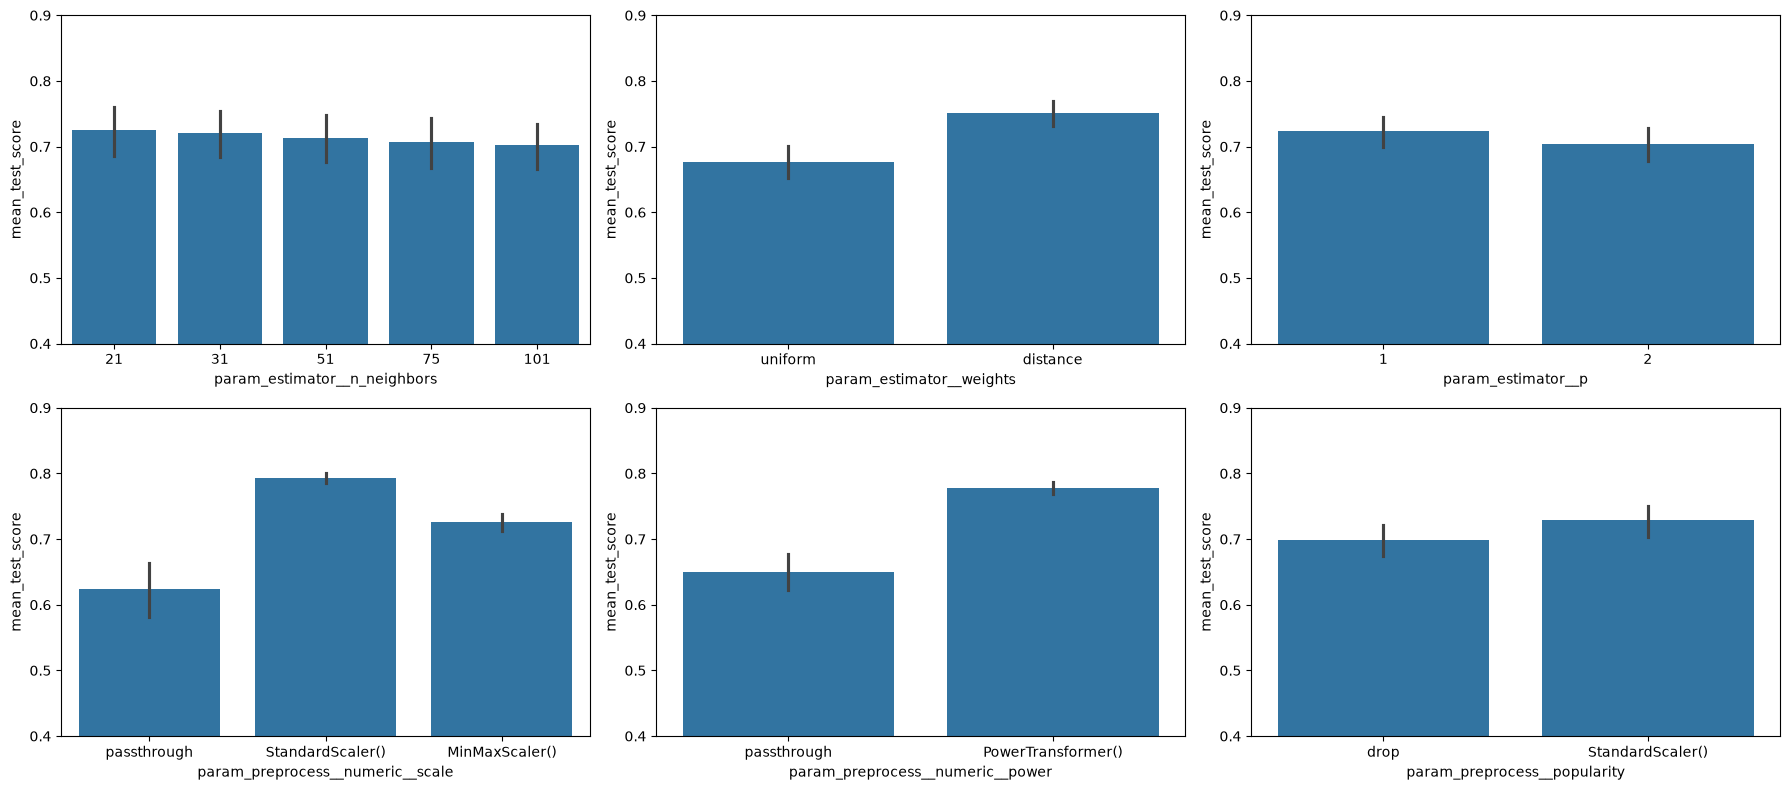

In [182]:
knn_results = pd.DataFrame(knn_grid.cv_results_)

# Turn the transformer objects into text so they can be plotted
for col in ['param_preprocess__numeric__power', 'param_preprocess__numeric__scale', 'param_preprocess__popularity']:
    knn_results[col] = knn_results[col].astype(str)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()
plot_params = ['param_estimator__n_neighbors', 'param_estimator__weights', 'param_estimator__p',
               'param_preprocess__numeric__scale', 'param_preprocess__numeric__power', 'param_preprocess__popularity']

for i, param in enumerate(plot_params):
    sns.barplot(data=knn_results, x=param, y='mean_test_score', ax=axes[i])
    axes[i].set_ylim(0.4, 0.9)

plt.tight_layout()
plt.show()

### Interpretation

The best KNN reaches a macro F1 of 0.851 in cross-validation, which is a bit better than the 
Decision Tree (0.833).

The best number of neighbours was 31. In my first search, 31 was the largest value I tested, so 
I extended the range up to 101 to check if even more neighbours would help. They didn't, so 31 is 
now in the middle of the range, and the range is wide enough. Using many neighbours makes sense 
here, since each genre has around 750 songs in the training data. Looking at 31 similar songs 
gives a more stable vote than looking at just a few.

The plots show that scaling matters a lot for KNN. Without any scaling, the model does much worse, 
because features with large values, like `duration_ms`, dominate the distance between songs. 
This confirms what I expected in the EDA. The `PowerTransformer` also improves the results, which 
fits with the skewed features I found in the histograms.

The best combination uses the `PowerTransformer` without an extra scaler. This looks strange at 
first, but the `PowerTransformer` already standardizes the values by default, so the data is still 
scaled.

Giving closer songs a bigger vote (`distance`) works better than giving every neighbour the same 
vote, and Manhattan distance (p=1) works slightly better than Euclidean distance (p=2). Keeping 
`popularity` gives a small improvement again.

In [183]:
# Prints the best cross-validation score for every value of every tuned parameter.
# This shows the same thing as the plots, but as numbers.
def summarize_results(grid):
    cv_results = pd.DataFrame(grid.cv_results_)
    for col in cv_results.columns:
        if col.startswith('param_'):
            # fillna('None') makes sure max_depth=None is included in the table
            values = cv_results[col].fillna('None').astype(str)
            best_per_value = cv_results.groupby(values)['mean_test_score'].max().rename_axis(None)
            print(f"\n{col.replace('param_', '')}:")
            print(best_per_value.round(3).to_string())

## Ensemble : Random Forest

A Random Forest trains many decision trees, each on a random part of the data and with a random 
selection of features. The final prediction is a vote between all the trees. Combining many trees 
usually reduces overfitting compared to a single tree.

In [184]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', RandomForestClassifier(random_state=42))
])

rf_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__n_estimators': [100, 300],
    'estimator__max_depth': [10, 20, None],
    'estimator__max_features': ['sqrt', 'log2']
}

rf_grid = GridSearchCV(rf_pipe, rf_params, scoring='f1_macro', n_jobs=-1)
rf_grid.fit(train_features, train_targets)

print(f"Best settings: {rf_grid.best_params_}")
print(f"Best cross-validation F1: {rf_grid.best_score_:.3f}")

Best settings: {'estimator__max_depth': 20, 'estimator__max_features': 'sqrt', 'estimator__n_estimators': 300, 'preprocess__categorical': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.899


In [185]:
summarize_results(rf_grid)


estimator__max_depth:
10      0.883
20      0.899
None    0.899

estimator__max_features:
log2    0.899
sqrt    0.899

estimator__n_estimators:
100    0.897
300    0.899

preprocess__categorical:
OneHotEncoder(handle_unknown='ignore')    0.894
passthrough                               0.899

preprocess__popularity:
StandardScaler()    0.899
drop                0.862


Deeper trees are better up to a point: 0.883 for depth 10 and 0.899 for depth 20. Having no limit 
at all gives the same score (0.899), so a deeper forest would not help and the range I tested was 
wide enough.

## Ensemble : Gradient Boosting

Gradient Boosting also combines many decision trees, but in a different way than a Random Forest. 
A Random Forest builds its trees independently and lets them vote. Gradient Boosting builds the 
trees one after another, and every new tree focuses on the mistakes the previous trees made.

I use `HistGradientBoostingClassifier`, which is a faster version of Gradient Boosting in scikit-learn. 
The regular version builds one tree per genre at every step, which is slow with six genres.

In [186]:

gb_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', HistGradientBoostingClassifier(random_state=42))
])

gb_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__learning_rate': [0.05, 0.1, 0.2],
    'estimator__max_iter': [100, 300],
    'estimator__max_depth': [3, 6, None]
}

gb_grid = GridSearchCV(gb_pipe, gb_params, scoring='f1_macro', n_jobs=-1)
gb_grid.fit(train_features, train_targets)

print(f"Best settings: {gb_grid.best_params_}")
print(f"Best cross-validation F1: {gb_grid.best_score_:.3f}")

Best settings: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 6, 'estimator__max_iter': 300, 'preprocess__categorical': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.908


In [187]:
summarize_results(gb_grid)


estimator__learning_rate:
0.05    0.908
0.1     0.908
0.2     0.908

estimator__max_depth:
3       0.903
6       0.908
None    0.908

estimator__max_iter:
100    0.907
300    0.908

preprocess__categorical:
OneHotEncoder(handle_unknown='ignore')    0.908
passthrough                               0.908

preprocess__popularity:
StandardScaler()    0.908
drop                0.863


In [188]:
# Prints the average score and the spread for the best settings of one search
def show_score(name, grid):
    table = pd.DataFrame(grid.cv_results_)     # all the results as a table
    best = table.loc[grid.best_index_]         # the row with the best settings
    print(f"{name}: {best['mean_test_score']:.3f} ± {best['std_test_score']:.3f}")

show_score('Decision Tree', dt_grid)
show_score('KNN', knn_grid)
show_score('Random Forest', rf_grid)
show_score('Gradient Boosting', gb_grid)

Decision Tree: 0.833 ± 0.008
KNN: 0.851 ± 0.013
Random Forest: 0.899 ± 0.008
Gradient Boosting: 0.908 ± 0.010


In [189]:
# The 5 fold scores behind the average
fold_columns = ['split0_test_score', 'split1_test_score', 'split2_test_score',
                'split3_test_score', 'split4_test_score']
print(pd.DataFrame(gb_grid.cv_results_).loc[gb_grid.best_index_, fold_columns])

split0_test_score    0.919444
split1_test_score    0.910159
split2_test_score    0.912449
split3_test_score    0.890162
split4_test_score    0.908043
Name: 39, dtype: float64


### Interpretation

The best Gradient Boosting reaches a macro F1 of 0.908 in cross-validation, which is a bit better 
than the Random Forest (0.899) and clearly better than the two baselines. The difference to the 
Random Forest is small though, so I would not say it is clearly better yet. 

Gradient Boosting scores 0.908 ± 0.010 and Random Forest 0.899 ± 0.008. The gap of 0.009 is about as 
big as the spread between the folds, so I can't say that one of them is better than the other. 
Both are clearly better than KNN (0.851 ± 0.013) and the Decision Tree (0.833 ± 0.008).


`popularity` has the biggest effect again: 0.908 when it is kept and 0.863 when it is dropped. 
Without `popularity`, Gradient Boosting and Random Forest get almost the same score (0.863 and 
0.862), so the small advantage only shows when `popularity` is used.

All three learning rates reach 0.908. A low learning rate can catch up if it gets enough trees, so 
in the best case it does not matter which one I choose. 100 and 300 trees give almost the same 
score (0.907 and 0.908), so the score has levelled out and I don't need to test more. Trees of 
depth 3 are slightly worse (0.903) than depth 6, and no depth limit gives the same score as 
depth 6. This is probably because each tree is already limited to 31 leaves by default. Keeping 
`key` and `time_signature` as numbers or one-hot encoded gives exactly the same result.

## Ensemble : Extra Trees

Extra Trees is very similar to a Random Forest: many decision trees that vote together. The difference 
is that a Random Forest searches for the best split value, while Extra Trees picks the split values at 
random. This makes each tree a bit weaker, but the trees are more different from each other, and the 
model trains faster.

In [190]:
et_pipe = Pipeline([ ('preprocess',make_preprocessor()), # What should happen to the data ! 
                     ('estimator',  ExtraTreesClassifier(random_state=42))]) # Learn from the prepared data 

In [191]:
extrees_param = {
    #Processing alternativ 
    'preprocess__popularity': ['drop',StandardScaler()],
    'preprocess__categorical':[OneHotEncoder(handle_unknown='ignore'),'passthrough'],
    #Model paramters 
    'estimator__n_estimators': [100,300], # How many trees i want to test it with , 100, 200 and 300 
    'estimator__max_depth': [10,20,30,None],
    'estimator__max_features': ['sqrt', 0.5,1.0]

    
    
}

In [192]:
extrees_grid = GridSearchCV(et_pipe,extrees_param,scoring='f1_macro',n_jobs=-1)
extrees_grid.fit(train_features,train_targets)


print(f"Best settings: {extrees_grid.best_params_}")
print(f"Best cross-validations F1 : {extrees_grid.best_score_:.3f}")

Best settings: {'estimator__max_depth': 20, 'estimator__max_features': 0.5, 'estimator__n_estimators': 300, 'preprocess__categorical': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validations F1 : 0.896


In [193]:
summarize_results(extrees_grid)
show_score('Extra trees', extrees_grid)


estimator__max_depth:
10      0.869
20      0.896
30      0.895
None    0.895

estimator__max_features:
0.5     0.896
1.0     0.895
sqrt    0.884

estimator__n_estimators:
100    0.896
300    0.896

preprocess__categorical:
OneHotEncoder(handle_unknown='ignore')    0.892
passthrough                               0.896

preprocess__popularity:
StandardScaler()    0.896
drop                0.853
Extra trees: 0.896 ± 0.009


### Interpretation

The best Extra Trees reaches a macro F1 of 0.896 ± 0.009 in cross-validation. This is about the same 
as the Random Forest (0.899 ± 0.008), and a bit below Gradient Boosting (0.908 ± 0.010). The gaps 
between the three ensembles are about as big as the spread between the folds, so I can't say that 
one of them is clearly the best. All three are clearly better than KNN and the Decision Tree.

`popularity` has the biggest effect again: 0.896 when it is kept and 0.853 when it is dropped.

A depth of 10 is too shallow (0.869), but from depth 20 the score levels out, so a deeper forest 
would not help. 100 and 300 trees give the same score, so 100 trees are enough. For `max_features`, 
`sqrt` is clearly worse (0.884) than half of the features (0.896) or all of them (0.895), which is 
the opposite of the Random Forest. This is probably because Extra Trees picks its split values at 
random, so it helps when each split can choose from more features. Keeping `key` and 
`time_signature` as numbers is slightly better than one-hot encoding (0.896 vs 0.892).

# ANN:  MLPClassifier 

## What is a neural network?

A neural network is a machine-learning model that learns how to make predictions from examples. In this project, it receives the processed numeric features of a song—such as energy, acousticness, duration, and encoded category information—and tries to predict the song’s genre. It does not begin by knowing what “high energy” or “classical music” means. Instead, it looks at many labelled songs and gradually learns which combinations of numeric patterns are associated with each genre.

A neural network is made from layers of small calculations called **neurons**. Each neuron receives input values and gives each input a learned **weight**. A weight represents how that input affects the neuron’s current calculation: a positive weight pushes its score upward, while a negative weight pushes it downward. The neuron also has a **bias**, which acts like a learned starting point or threshold. Both weights and biases begin as small random values and are adjusted during training.

After combining its inputs, a neuron uses an **activation function**. In hidden layers, a common activation function is ReLU, which changes negative values to zero and keeps positive values. Activations are important because they allow the network to learn complex patterns instead of only simple straight-line relationships. Several layers of neurons can therefore learn increasingly useful combinations of the original song features.

At the end of the network, the model produces a score for every possible genre. For a problem where each song has one genre, softmax converts these scores into probabilities that add up to 100%. For example, the model might predict a 70% probability of Rock, 20% Pop, and 10% Classical, then choose Rock as its prediction.

During training, the network compares its predicted probabilities with the true genre label. It calculates a **loss**, which is a number representing how wrong the prediction was. A low loss means the model gave high probability to the correct genre; a high loss means it was confidently wrong. Using backpropagation and gradient descent, the model makes small adjustments to its weights and biases to reduce the loss. Repeating this process over many songs and many training rounds allows the neural network to improve its predictions.

In [194]:
mlp_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', MLPClassifier(max_iter=300,early_stopping=True, random_state=42))
])

In [195]:
mlp_params = {
    # Processing alternatives
    'preprocess__numeric__power': ['passthrough', PowerTransformer()],
    'preprocess__numeric__scale': [StandardScaler(), MinMaxScaler()],
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__hidden_layer_sizes': [(64,), (128, 64), (128, 64, 32)],
    'estimator__activation': ['relu', 'tanh'],
    'estimator__alpha': [1e-4, 1e-3, 1e-2],
    'estimator__learning_rate_init': [1e-3, 3e-3, 1e-2, 3e-2]
}

In [196]:
from sklearn.model_selection import RandomizedSearchCV

mlp_search = RandomizedSearchCV(mlp_pipe, mlp_params, n_iter=40, scoring='f1_macro',
                                random_state=42, n_jobs=-1)
mlp_search.fit(train_features, train_targets)

print(f"Best settings: {mlp_search.best_params_}")
print(f"Best cross-validation F1: {mlp_search.best_score_:.3f}")

Best settings: {'preprocess__popularity': StandardScaler(), 'preprocess__numeric__scale': StandardScaler(), 'preprocess__numeric__power': 'passthrough', 'preprocess__categorical': 'passthrough', 'estimator__learning_rate_init': 0.003, 'estimator__hidden_layer_sizes': (128, 64, 32), 'estimator__alpha': 0.001, 'estimator__activation': 'tanh'}
Best cross-validation F1: 0.856


In [197]:
summarize_results(mlp_search)
show_score('MLP', mlp_search)


preprocess__popularity:
StandardScaler()    0.856
drop                0.825

preprocess__numeric__scale:
MinMaxScaler()      0.846
StandardScaler()    0.856

preprocess__numeric__power:
PowerTransformer()    0.853
passthrough           0.856

preprocess__categorical:
OneHotEncoder(handle_unknown='ignore')    0.853
passthrough                               0.856

estimator__learning_rate_init:
0.001    0.835
0.003    0.856
0.01     0.853
0.03     0.852

estimator__hidden_layer_sizes:
(128, 64)        0.853
(128, 64, 32)    0.856
(64,)            0.852

estimator__alpha:
0.0001    0.853
0.001     0.856
0.01      0.847

estimator__activation:
relu    0.853
tanh    0.856
MLP: 0.856 ± 0.008


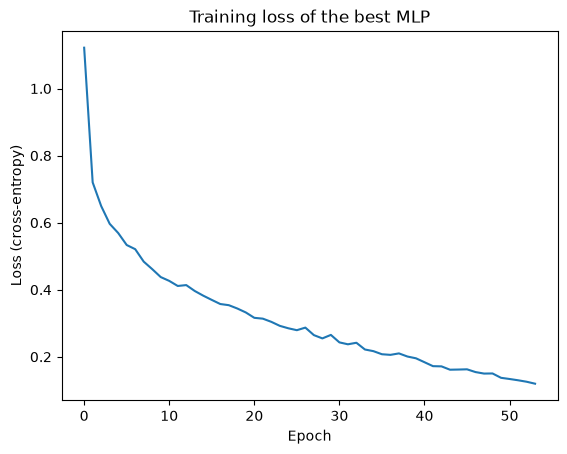

In [198]:
best_mlp = mlp_search.best_estimator_.named_steps['estimator']

plt.plot(best_mlp.loss_curve_)
plt.xlabel('Epoch')
plt.ylabel('Loss (cross-entropy)')
plt.title('Training loss of the best MLP')
plt.show()

### Interpretation

The best MLP reaches a macro F1 of 0.856 ± 0.008. This is about the same as the Keras network 
(0.858 ± 0.013) and KNN (0.851 ± 0.013), a bit better than the Decision Tree (0.833), and clearly 
worse than the three tree ensembles (0.896 to 0.908).

`popularity` has the biggest effect again: 0.856 when it is kept and 0.825 when it is dropped. 
Scaling matters for a neural network: StandardScaler (0.856) is better than MinMaxScaler (0.846), 
the same as for KNN.

In my first search the best learning rate was 0.01, which was the highest value I tested, so I 
extended the range to 0.03. In the new search the best learning rate is 0.003, which is in the middle 
of the range: 0.001 is clearly worse (0.835), and 0.01 and 0.03 are slightly worse (0.853 and 0.852). 
So the range is now wide enough.

The other settings only differ by 0.004 or less, which is smaller than the spread between the folds, 
so I can't say that they matter: the number of hidden layers (0.856, 0.853 and 0.852), tanh vs ReLU 
(0.856 vs 0.853), the PowerTransformer (0.853 with and 0.856 without) and the encoding of `key` and 
`time_signature` (0.853 one-hot and 0.856 as numbers). The strongest regularization (`alpha` 0.01) is 
slightly worse (0.847) than 0.0001 and 0.001 (0.853 and 0.856).



In [199]:
import os
os.environ["KERAS_BACKEND"] = "torch"      # must be set BEFORE keras is imported
import keras
import scikeras
print(keras.__version__, keras.backend.backend(), scikeras.__version__)

3.15.1 torch 0.13.0


In [200]:
def build_model(meta, hidden_units=(64, 32), dropout=0.0):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(meta["n_features_in_"],)))        # one input per column
    for units in hidden_units:
        model.add(keras.layers.Dense(units, activation='relu'))           # a hidden layer
        model.add(keras.layers.Dropout(dropout))                          # switch off a share of neurons
    model.add(keras.layers.Dense(meta["n_classes_"], activation='softmax'))   # output: one probability per genre
    return model

In [201]:
keras_clf = KerasClassifier(
    model=build_model,
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    optimizer__learning_rate=1e-3,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
    verbose=0,
    random_state=42
)

In [202]:
keras_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', keras_clf)
])

# validation_split takes the LAST 10% of the data, and the training data is sorted by genre.
# So I shuffle a copy first, otherwise the validation set would only contain one genre.
keras_features = train_features.sample(frac=1, random_state=42)
keras_targets = train_targets.loc[keras_features.index]

In [203]:
keras_params = {
    # Processing alternatives
    'preprocess__numeric__power': ['passthrough', PowerTransformer()],
    'preprocess__popularity': ['drop', StandardScaler()],
    # Model parameters
    'estimator__model__hidden_units': [(64,), (128, 64), (128, 64, 32)],
    'estimator__model__dropout': [0.0, 0.2, 0.4],
    'estimator__optimizer__learning_rate': [1e-3, 3e-3, 1e-2],
    'estimator__batch_size': [32, 128]
}

In [204]:
keras_search = RandomizedSearchCV(keras_pipe, keras_params, n_iter=15, scoring='f1_macro',
                                  random_state=42, n_jobs=1)
keras_search.fit(keras_features, keras_targets)

print(f"Best settings: {keras_search.best_params_}")
print(f"Best cross-validation F1: {keras_search.best_score_:.3f}")

Best settings: {'preprocess__popularity': StandardScaler(), 'preprocess__numeric__power': PowerTransformer(), 'estimator__optimizer__learning_rate': 0.001, 'estimator__model__hidden_units': (128, 64), 'estimator__model__dropout': 0.2, 'estimator__batch_size': 128}
Best cross-validation F1: 0.858


In [205]:
summarize_results(keras_search)
show_score('Keras network', keras_search)


preprocess__popularity:
StandardScaler()    0.858
drop                0.805

preprocess__numeric__power:
PowerTransformer()    0.858
passthrough           0.851

estimator__optimizer__learning_rate:
0.001    0.858
0.003    0.853
0.01     0.849

estimator__model__hidden_units:
(128, 64)        0.858
(128, 64, 32)    0.853
(64,)            0.843

estimator__model__dropout:
0.0    0.856
0.2    0.858
0.4    0.851

estimator__batch_size:
128    0.858
32     0.856
Keras network: 0.858 ± 0.013


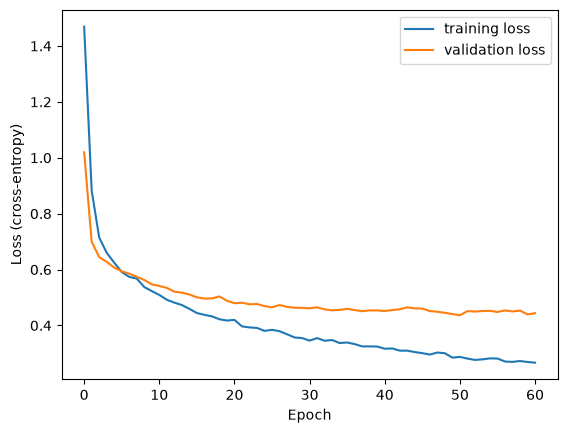

In [206]:
history = keras_search.best_estimator_.named_steps['estimator'].history_

plt.plot(history['loss'], label='training loss')
plt.plot(history['val_loss'], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (cross-entropy)')
plt.legend()
plt.show()

### Interpretation

The best Keras network reaches a macro F1 of 0.858 ± 0.013, which is the same as the MLP 
(0.859 ± 0.008) and about the same as KNN (0.851 ± 0.013). The three tree ensembles are clearly better 
(0.896 to 0.908).

`popularity` has the biggest effect of all: 0.858 when it is kept and 0.805 when it is dropped. 
The best network has two hidden layers (128 and 64 neurons), while one layer with 64 neurons is worse 
(0.843). The other settings only differ by 0.007 or less, which is smaller than the spread between 
the folds, so I can't say that they matter: the PowerTransformer, dropout (0.0, 0.2 and 0.4) and the 
batch size (32 and 128).

The best learning rate was 0.001, which was the lowest value I tested. I checked a lower value 
(0.0003), and it was worse (0.845), so 0.001 is the best.

The loss curves show that the training loss keeps falling, while the validation loss flattens out 
after about 20 epochs. This is the start of overfitting. Early stopping ended the training at about 
epoch 60 and restored the best weights. Dropout made the network overfit slower than the MLP, but the 
final score is the same.

In [209]:

for lr in [0.0003, 0.001]:
    model = clone(keras_pipe)                                      # a fresh, unfitted copy of the pipeline
    model.set_params(**keras_search.best_params_)                  # the best settings from the search
    model.set_params(estimator__optimizer__learning_rate=lr)       # change only the learning rate
    scores = cross_val_score(model, keras_features, keras_targets, cv=5, scoring='f1_macro')
    print(f"learning rate {lr}: {scores.mean():.3f} ± {scores.std():.3f}")

learning rate 0.0003: 0.852 ± 0.014
learning rate 0.001: 0.853 ± 0.015


# EVALUATION

All seven models are tuned with cross-validation on the training data. Now, for the first and only 
time, I test them on the test set, which none of the models have seen. After this, I don't change 
any model because of these results.

In [212]:
tuned_models = {
    'Decision Tree': dt_grid,
    'KNN': knn_grid,
    'Random Forest': rf_grid,
    'Extra Trees': extrees_grid,
    'Gradient Boosting': gb_grid,
    'MLP': mlp_search,
    'Keras network': keras_search
}

test_predictions = {name: model.predict(test_features) for name, model in tuned_models.items()}

In [215]:
test_results = {}
for name, model in tuned_models.items():
    pred = test_predictions[name]
    test_results[name] = {
        'Accuracy': accuracy_score(test_targets, pred),
        'Precision': precision_score(test_targets, pred, average='macro'),
        'Recall': recall_score(test_targets, pred, average='macro'),
        'F1': f1_score(test_targets, pred, average='macro'),
        'ROC-AUC': roc_auc_score(test_targets, model.predict_proba(test_features), multi_class='ovr', average='macro')
    }

test_results_df = pd.DataFrame(test_results).round(3)
test_results_df

,Decision Tree,KNN,Random Forest,Extra Trees,Gradient Boosting,MLP,Keras network
Accuracy,0.843,0.862,0.911,0.910,0.927,0.879,0.864
Precision,0.843,0.865,0.912,0.911,0.927,0.880,0.866
Recall,0.844,0.862,0.911,0.911,0.927,0.879,0.865
F1,0.843,0.862,0.911,0.910,0.927,0.879,0.865
ROC-AUC,0.912,0.983,0.991,0.991,0.993,0.982,0.983


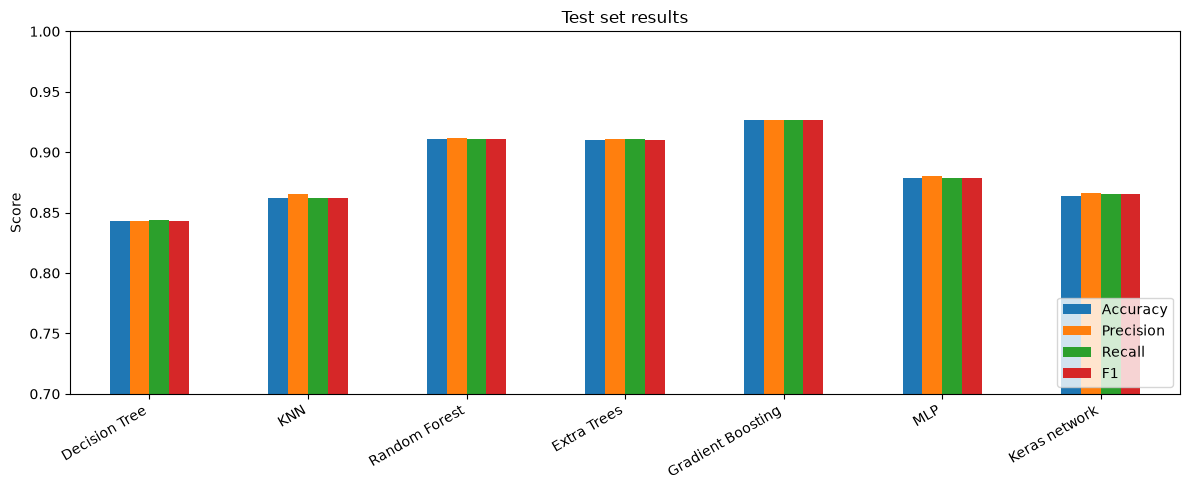

In [216]:
test_results_df.T[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(12, 5))
plt.title('Test set results')
plt.ylabel('Score')
plt.ylim(0.7, 1.0)        # zoomed in so the differences are visible
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

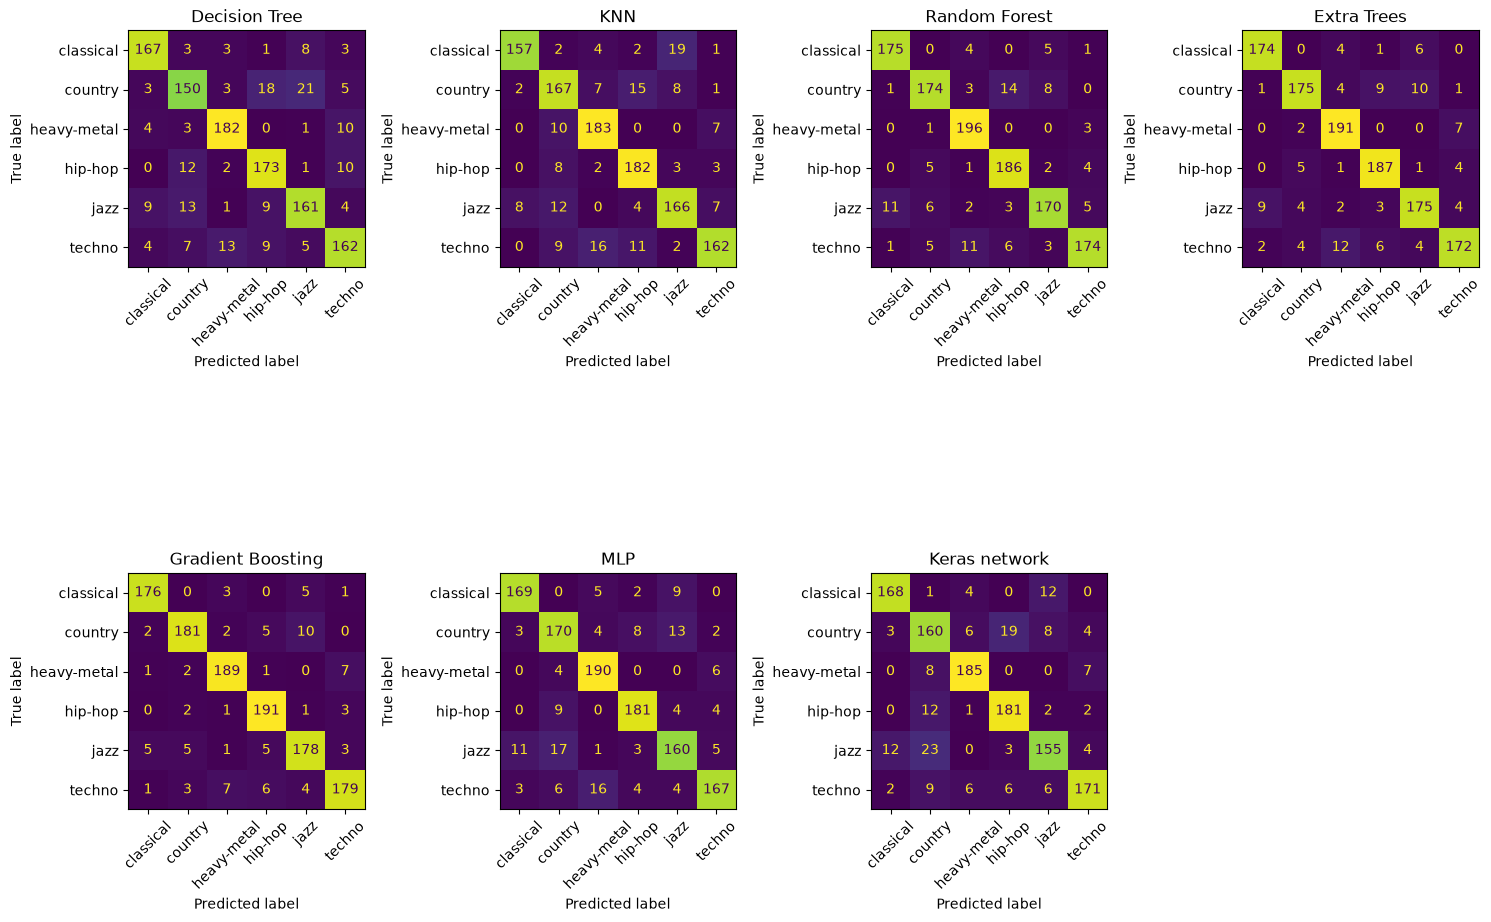

In [224]:
fig, axes = plt.subplots(2, 4, figsize=(15, 11))
axes = axes.flatten()

for ax, (name, pred) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(test_targets, pred, display_labels=label_encoder.classes_,
                                            ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(name)

axes[-1].set_visible(False)      # 7 models in 8 slots: hide the empty one
plt.tight_layout()
plt.show()

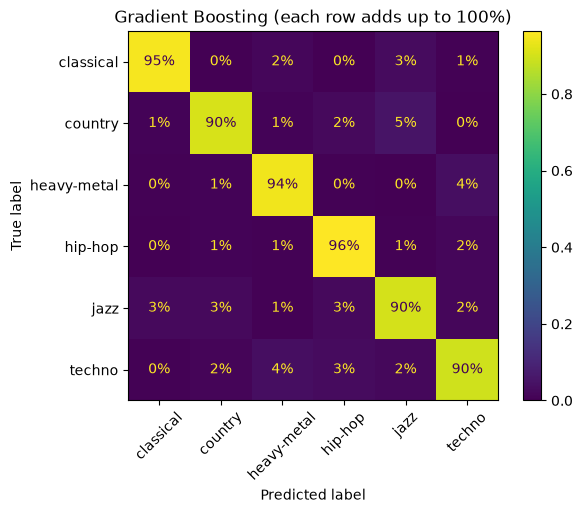

              precision    recall  f1-score   support

   classical       0.95      0.95      0.95       185
     country       0.94      0.91      0.92       200
 heavy-metal       0.93      0.94      0.94       200
     hip-hop       0.92      0.96      0.94       198
        jazz       0.90      0.90      0.90       197
      techno       0.93      0.90      0.91       200

    accuracy                           0.93      1180
   macro avg       0.93      0.93      0.93      1180
weighted avg       0.93      0.93      0.93      1180



In [227]:
best_pred = test_predictions['Gradient Boosting']

ConfusionMatrixDisplay.from_predictions(test_targets, best_pred, display_labels=label_encoder.classes_,
                                        normalize='true', values_format='.0%', xticks_rotation=45)
plt.title('Gradient Boosting (each row adds up to 100%)')
plt.show()

print(classification_report(test_targets, best_pred, target_names=label_encoder.classes_))

### Interpretation

I look at Gradient Boosting in more detail, because it had the best cross-validation score.

The classification report shows that all six genres have an F1 between 0.90 and 0.95, so the model 
works well for every genre and none of them is left behind. Classical is the easiest genre (F1 0.95), 
followed by hip-hop and heavy-metal (0.94). Jazz is the hardest (F1 0.90), followed by techno (0.91). 
Macro average and weighted average are both 0.93, because the genres are nearly balanced (185 to 200 
songs each).

Precision and recall are not always equal. Hip-hop has a high recall (0.96) but a lower precision 
(0.92), which means that almost all hip-hop songs are found, but some songs from other genres are 
also called hip-hop. For country it is the opposite: precision 0.94 and recall 0.91, so the model is 
quite sure when it says country, but it misses some country songs.

The normalized confusion matrix shows where the mistakes go. The biggest ones are country songs 
predicted as jazz (5%), heavy-metal and techno mixed up in both directions (4% each), and classical 
and jazz mixed up in both directions (3% each). Jazz songs are spread over several other genres (3% 
each to classical, country and hip-hop). This fits with the EDA, where classical and jazz were both 
calm and acoustic, and heavy-metal and techno were both energetic and not acoustic.

In [229]:
test_probabilities = {name: model.predict_proba(test_features) for name, model in tuned_models.items()}

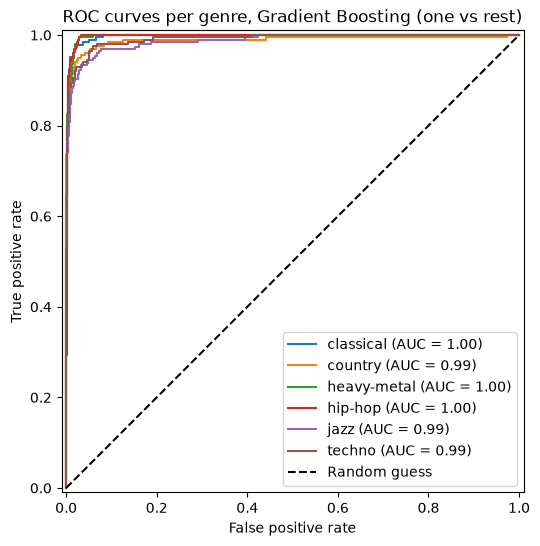

In [230]:
best_proba = test_probabilities['Gradient Boosting']

fig, ax = plt.subplots(figsize=(7, 6))
for i, genre in enumerate(label_encoder.classes_):
    RocCurveDisplay.from_predictions(test_targets == i, best_proba[:, i], name=genre, ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC curves per genre, Gradient Boosting (one vs rest)')
ax.legend(loc='lower right')
plt.show()

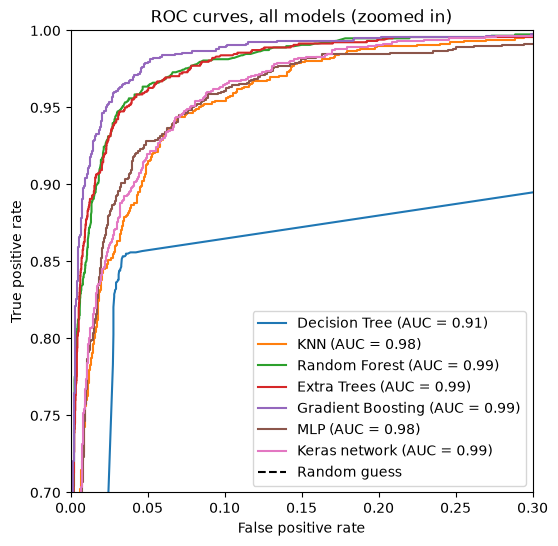

In [231]:
test_binary = label_binarize(test_targets, classes=range(6))      # one yes/no column per genre

fig, ax = plt.subplots(figsize=(7, 6))
for name, proba in test_probabilities.items():
    RocCurveDisplay.from_predictions(test_binary.ravel(), proba.ravel(), name=name, ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_xlim(0, 0.3)       # zoomed in on the top-left corner, otherwise the curves overlap
ax.set_ylim(0.7, 1.0)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC curves, all models (zoomed in)')
ax.legend(loc='lower right')
plt.show()

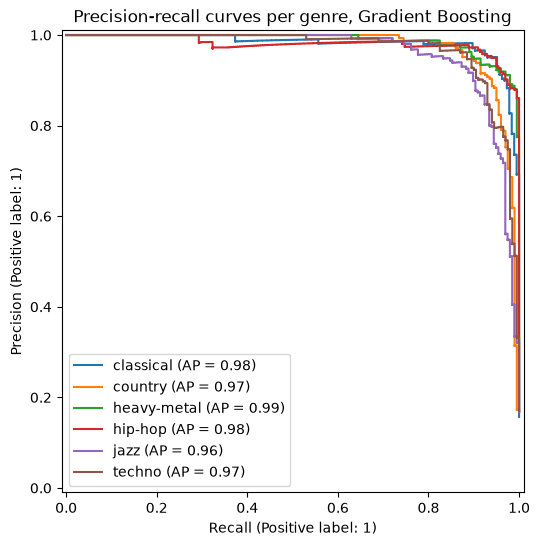

In [232]:
fig, ax = plt.subplots(figsize=(7, 6))
for i, genre in enumerate(label_encoder.classes_):
    PrecisionRecallDisplay.from_predictions(test_targets == i, best_proba[:, i], name=genre, ax=ax)

ax.set_title('Precision-recall curves per genre, Gradient Boosting')
ax.legend(loc='lower left')
plt.show()